# DecPyMC-3-Multi-Attribute : Utilite Multi-Attributs
**Serie** : Programmation Probabiliste avec PyMC (3/7)  
**Duree estimee** : 50 minutes  
**Prerequis** : [DecPyMC-2-Utility-Money](DecPyMC-2-Utility-Money.ipynb) (utilite de l'argent, aversion au risque)

***

## Objectifs

- Modeliser des decisions avec **plusieurs critères**
- Comprendre l'**indépendance preferentielle**
- Appliquer les **theoremes d'additivite et multiplicativite**
- Utiliser la méthode **SMART** pour la decision multi-critères
- Inferer les **poids MAUT** par apprentissage bayesien avec PyMC

***

## Navigation

| Précédent | Suivant |
|-----------|--------|
| [DecPyMC-2-Utility-Money](DecPyMC-2-Utility-Money.ipynb) | [DecPyMC-4-Decision-Networks](DecPyMC-4-Decision-Networks.ipynb) |

## 1. Introduction : Decisions Multi-Critères

### Le problème

La plupart des decisions reelles impliquent plusieurs critères :

| Decision | Critères |
|----------|----------|
| Achat voiture | Prix, securite, consommation, confort |
| Choix de carriere | Salaire, equilibre vie/travail, passion, securite emploi |
| Investissement | Rendement, risque, liquidite, impact ESG |

Comment combiner ces critères en une **decision rationnelle** ?

### Approches possibles

1. **Méthode lexicographique** : Trier par critere le plus important, puis par le second...
2. **Ponderation simple** : V(x) = $\sum w_i \times v_i(x_i)$
3. **Théorie de l'utilite multi-attributs (MAUT)** : Fondee sur les axiomes d'utilite esperee de **von Neumann & Morgenstern (1944)** etendue au cas multi-attributs

### Preparation de l'environnement

In [1]:
import numpy as np
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt
from dataclasses import dataclass
from typing import List
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

print(f"PyMC version : {pm.__version__}")
print(f"ArviZ version : {az.__version__}")

g++ not available, if using conda: `conda install gxx`


PyMC version : 6.3.2
ArviZ version : 1.3.0


### Jeu de données : choix de voiture

Nous definissons 4 options de voiture avec 4 attributs (prix, securite, consommation, confort). Aucune ne domine sur tous les critères, ce qui necessite une méthode de decision multi-critères structuree.

In [2]:
@dataclass
class Voiture:
    nom: str
    prix: float          # EUR
    securite: int        # 1-5 etoiles
    consommation: float  # L/100km
    confort: int         # 1-10

voitures = [
    Voiture("Economique A", 15000, 3, 5.0, 6),
    Voiture("Familiale B",  28000, 5, 6.5, 8),
    Voiture("Sport C",     45000, 4, 9.0, 7),
    Voiture("Hybride D",   32000, 5, 4.0, 8),
]

print("Options disponibles :\n")
print(f"{'Nom':<16} | {'Prix':>8} | {'Securite':>8} | {'Conso':>6} | {'Confort':>7}")
print("-" * 16 + "-+-" + "-" * 8 + "-+-" + "-" * 8 + "-+-" + "-" * 6 + "-+-" + "-" * 7)
for v in voitures:
    print(f"{v.nom:<16} | {v.prix:>8,.0f} | {v.securite:>8} | {v.consommation:>6.1f} | {v.confort:>7}")

Options disponibles :

Nom              |     Prix | Securite |  Conso | Confort
-----------------+----------+----------+--------+--------
Economique A     |   15,000 |        3 |    5.0 |       6
Familiale B      |   28,000 |        5 |    6.5 |       8
Sport C          |   45,000 |        4 |    9.0 |       7
Hybride D        |   32,000 |        5 |    4.0 |       8


### Interpretation du tableau des options

| Voiture | Profil | Points forts | Points faibles |
|---------|--------|--------------|----------------|
| **Economique A** | Budget-friendly | Prix bas, bonne conso | Securite moyenne, confort limite |
| **Familiale B** | Equilibree | Securite max, bon confort | Prix eleve, consommation moyenne |
| **Sport C** | Performance | Securite correcte | Prix très eleve, forte conso |
| **Hybride D** | Eco-responsable | Securite max, conso min | Prix assez eleve |

> **Observation cle** : Aucune voiture ne domine les autres sur tous les critères. C'est précisément ce type de situation qui necessite une méthode de decision multi-critères structuree.

## 2. Fonctions de Valeur vs Fonctions d'Utilite

### Distinction importante

| Type | Contexte | Propriete |
|------|----------|----------|
| **Fonction de valeur V(x)** | Certitude | Préférences sur outcomes certains |
| **Fonction d'utilite U(x)** | Incertitude | Préférences sur loteries |

### En multi-attributs

- **Valeur** : V(prix, securite, conso, confort) represente vos préférences sous certitude
- **Utilite** : U(.) integre en plus votre aversion au risque sur chaque attribut

Dans ce notebook, nous commencerons par les fonctions de valeur (plus simples), puis passerons aux fonctions d'utilite.

## 3. Indépendance Preferentielle

L'indépendance preferentielle est la cle qui permet de decomposer un problème multi-critères en sous-problemes simples.

### Definition

> L'attribut X est **preferentiellement indépendant** de Y si :
> Les préférences sur X ne dependent pas du niveau de Y

### Test pratique

1. Fixez Securite = niveau bas (ex: 2 etoiles) et comparez deux prix
2. Fixez Securite = niveau haut (ex: 5 etoiles) et comparez les mêmes prix
3. Si votre préférence est la même dans les deux cas, Prix est indépendant de Securite

### Indépendance mutuelle

> Les attributs {X, Y, Z} sont **mutuellement preferentiellement independants** si :
> Chaque sous-ensemble est preferentiellement indépendant de son complement

Cette condition permet d'utiliser des formes **additives** ou **multiplicatives** simples.

In [3]:
print("Test d'independance : Prix vs Securite\n")
print("Question : Preferez-vous A ou B ?\n")

print("Contexte 1 (Securite = 3 etoiles) :")
print("  A : Prix = 15 000 EUR")
print("  B : Prix = 20 000 EUR")
print("  => Vous preferez probablement A (moins cher)\n")

print("Contexte 2 (Securite = 5 etoiles) :")
print("  A : Prix = 15 000 EUR")
print("  B : Prix = 20 000 EUR")
print("  => Preferez-vous toujours A ?\n")

print("Si votre reponse est la meme dans les deux contextes,")
print("alors Prix et Securite sont preferentiellement independants.")

Test d'independance : Prix vs Securite

Question : Preferez-vous A ou B ?

Contexte 1 (Securite = 3 etoiles) :
  A : Prix = 15 000 EUR
  B : Prix = 20 000 EUR
  => Vous preferez probablement A (moins cher)

Contexte 2 (Securite = 5 etoiles) :
  A : Prix = 15 000 EUR
  B : Prix = 20 000 EUR
  => Preferez-vous toujours A ?

Si votre reponse est la meme dans les deux contextes,
alors Prix et Securite sont preferentiellement independants.


## 4. Theoreme d'Additivite (Debreu-Gorman)

Ce résultat d'additivite est etabli par **Debreu (1960)** et generalise par **Gorman (1968)** sous l'hypothese d'indépendance preferentielle mutuelle des attributs.

### Enonce

> Si les attributs $X_1, X_2, \ldots, X_n$ sont mutuellement preferentiellement independants,
> alors la fonction de valeur est **additive** :
>
> $$V(x_1, x_2, \ldots, x_n) = \sum_i w_i \cdot v_i(x_i)$$

Ou :
- $v_i(x_i)$ est la fonction de valeur marginale pour l'attribut i (normalisee 0-1)
- $w_i$ est le poids de l'attribut i ($\sum w_i = 1$)

In [4]:
# Fonctions de valeur marginale (normalisées 0-1)
def v_prix(prix, prix_min=15000, prix_max=45000):
    """Plus bas = mieux (inverser)."""
    return 1 - (prix - prix_min) / (prix_max - prix_min)

def v_securite(sec, sec_min=1, sec_max=5):
    """Plus haut = mieux."""
    return (sec - sec_min) / (sec_max - sec_min)

def v_conso(conso, conso_min=4, conso_max=10):
    """Plus bas = mieux (inverser)."""
    return 1 - (conso - conso_min) / (conso_max - conso_min)

def v_confort(confort, conf_min=1, conf_max=10):
    """Plus haut = mieux."""
    return (confort - conf_min) / (conf_max - conf_min)


# Poids (swing weights)
w_prix = 0.35
w_securite = 0.30
w_conso = 0.20
w_confort = 0.15

print(f"Poids : Prix={w_prix:.0%}, Securite={w_securite:.0%}, Conso={w_conso:.0%}, Confort={w_confort:.0%}\n")

print(f"{'Voiture':<16} | {'v_prix':>6} | {'v_sec':>6} | {'v_conso':>6} | {'v_conf':>6} | {'V_total':>7}")
print("-" * 16 + "-+-" + "-" * 6 + "-+-" + "-" * 6 + "-+-" + "-" * 6 + "-+-" + "-" * 6 + "-+-" + "-" * 7)

for v in voitures:
    vp = v_prix(v.prix)
    vs = v_securite(v.securite)
    vc = v_conso(v.consommation)
    vf = v_confort(v.confort)
    V = w_prix * vp + w_securite * vs + w_conso * vc + w_confort * vf
    print(f"{v.nom:<16} | {vp:>6.3f} | {vs:>6.3f} | {vc:>6.3f} | {vf:>6.3f} | {V:>7.3f}")

meilleure = max(voitures, key=lambda v: (
    w_prix * v_prix(v.prix) + w_securite * v_securite(v.securite) +
    w_conso * v_conso(v.consommation) + w_confort * v_confort(v.confort)
))
print(f"\n=> Meilleur choix : {meilleure.nom}")

Poids : Prix=35%, Securite=30%, Conso=20%, Confort=15%

Voiture          | v_prix |  v_sec | v_conso | v_conf | V_total
-----------------+--------+--------+--------+--------+--------
Economique A     |  1.000 |  0.500 |  0.833 |  0.556 |   0.750
Familiale B      |  0.567 |  1.000 |  0.583 |  0.778 |   0.732
Sport C          |  0.000 |  0.750 |  0.167 |  0.667 |   0.358
Hybride D        |  0.433 |  1.000 |  1.000 |  0.778 |   0.768

=> Meilleur choix : Hybride D


### Lecture du résultat — un classement à dix-huit millièmes

Quatre options, quatre scores : 0,768, 0,750, 0,732, 0,358. Le premier réflexe est de lire « Hybride D gagne ». Le second, plus utile, est de regarder de combien.

L'écart entre la première et la deuxième place vaut 0,018 ; entre la première et la troisième, 0,036. Autrement dit, les trois premières options tiennent dans une bande de 3,6 points de pourcentage, quand la quatrième en est distante de 0,410. À cette résolution, le modèle ne dit pas que D est meilleur : il dit que **D, A et B sont indiscernables** et que C est seul, nettement derrière.

La forme additive ne sait pas exprimer cette nuance. Elle additionne des contributions pondérées et rend un nombre, sans jamais dire à partir de quel écart le résultat cesse d'être un artefact d'arrondi ou de pondération. Un classement complet de quatre options triées sur un écart de 0,018 est une précision que ni les données d'entrée — des notes de 1 à 10 et des prix au millier d'euros — ni les poids, donnés à cinq points de pourcentage près, ne peuvent soutenir.

Ce que le tableau porte de solide est donc ailleurs. D'une part, la décomposition de la cellule suivante montrera que Sport C, elle, est **dominée colonne par colonne** par Familiale B et Hybride D : son score bas n'est pas un arbitrage, c'est une infériorité sur chaque attribut pris séparément. D'autre part, le gagnant ne gagne pas par un attribut dominant mais par la somme de deux seconds rangs. La suite du carnet montre ce qu'il advient de ce mince écart quand la méthode d'élicitation change.


### Exercice 1 : Poids personnalises et comparaison de profils

Le classement des voitures depend directement des poids choisis. Un profil **eco-responsable** privilegiera la consommation, tandis qu'un profil **budget** mettra le prix en tete.

**Objectif** : Définir deux jeux de poids alternatifs et comparer les classements obtenus.

**Indices** :
- **Étape** 1 : Définir un profil eco-responsable (`w_conso=0.40, w_securite=0.25, w_prix=0.20, w_confort=0.15`)
- **Étape** 2 : Définir un profil budget (`w_prix=0.50, w_securite=0.25, w_conso=0.15, w_confort=0.10`)
- **Étape** 3 : Pour chaque profil, calculer `V_total` pour les 4 voitures avec la formule additive

In [5]:
# Exercice 1 : Poids personnalises et comparaison de profils
# TODO étudiant : définir 2 jeux de poids et comparer les classements

# À compléter : profil eco-responsable
w_eco = None  # TODO étudiant : dictionnaire {prix, sécurité, conso, confort} sommant a 1

# À compléter : profil budget
w_budget = None  # TODO étudiant : dictionnaire {prix, sécurité, conso, confort} sommant a 1

# À compléter : pour chaque profil, calculer V_total de chaque voiture
# Indice : V = w_prix * v_prix(prix) + w_securite * v_securite(sec) + w_conso * v_conso(conso) + w_confort * v_confort(confort)
# À compléter : afficher le classement pour chaque profil

print("Exercice a completer : comparer les classements avec des poids personnalises.")

Exercice a completer : comparer les classements avec des poids personnalises.


Decomposition des valeurs par attribut pour visualiser la contribution de chaque critere.

In [6]:
print("Decomposition de la valeur multi-attributs :\n")
print(f"{'Voiture':<16} | {'Prix':>7} | {'Securite':>9} | {'Conso':>7} | {'Confort':>7} | {'V':>5}")
print(f"{'':16}   {'(w=35%)':>7}   {'(w=30%)':>9}   {'(w=20%)':>7}   {'(w=15%)':>7}")
print("-" * 16 + "-+-" + "-" * 7 + "-+-" + "-" * 9 + "-+-" + "-" * 7 + "-+-" + "-" * 7 + "-+-" + "-" * 5)

for v in voitures:
    vp = v_prix(v.prix)
    vs = v_securite(v.securite)
    vc = v_conso(v.consommation)
    vf = v_confort(v.confort)
    cp = w_prix * vp
    cs = w_securite * vs
    cc = w_conso * vc
    cf = w_confort * vf
    print(f"{v.nom:<16} | {cp:>7.3f} | {cs:>9.3f} | {cc:>7.3f} | {cf:>7.3f} | {cp+cs+cc+cf:>5.3f}")

print("\nChaque colonne = contribution ponderee de l'attribut (wi * vi)")
print("V total = somme des contributions")

Decomposition de la valeur multi-attributs :

Voiture          |    Prix |  Securite |   Conso | Confort |     V
                   (w=35%)     (w=30%)   (w=20%)   (w=15%)
-----------------+---------+-----------+---------+---------+------
Economique A     |   0.350 |     0.150 |   0.167 |   0.083 | 0.750
Familiale B      |   0.198 |     0.300 |   0.117 |   0.117 | 0.732
Sport C          |   0.000 |     0.225 |   0.033 |   0.100 | 0.358
Hybride D        |   0.152 |     0.300 |   0.200 |   0.117 | 0.768

Chaque colonne = contribution ponderee de l'attribut (wi * vi)
V total = somme des contributions


### Lecture du résultat — deux finalistes qui gagnent sur des attributs disjoints

La décomposition rend lisible ce que les totaux masquaient. Economique A tire 0,350 de son prix — le maximum de cette colonne — mais seulement 0,150 de sa sécurité et 0,083 de son confort. Hybride D fait l'inverse : 0,300 de sécurité et 0,200 de consommation, les deux maxima, pour 0,152 de prix. Aucune des deux n'est meilleure dans l'absolu ; elles sont **bonnes sur des attributs différents**.

Les 0,018 qui séparent leurs totaux, 0,768 contre 0,750, ne sont donc pas la mesure d'une supériorité : c'est le résidu d'un arbitrage entre deux profils opposés, calculé avec des poids particuliers. Changez le poids du prix de quelques points et le classement bascule, alors que les données sur les voitures, elles, n'ont pas changé d'un iota.

Familiale B occupe une position intéressante : 0,300 en sécurité comme D, mais 0,198 en prix et 0,117 en consommation. Elle perd l'arbitrage sur la consommation, pas sur la sécurité. C'est le genre de distinction qu'une recommandation doit énoncer — « D plutôt que B, et la raison est la consommation » — au lieu de se contenter d'un rang.

Reste Sport C, à 0,358, et c'est le cas le plus instructif. Ses contributions valent 0,000 en prix, 0,225 en sécurité, 0,033 en consommation et 0,100 en confort. Or Familiale B affiche 0,198 / 0,300 / 0,117 / 0,117 et Hybride D 0,152 / 0,300 / 0,200 / 0,117 : les deux la dépassent sur **chacune des quatre colonnes**. Sur des attributs comparables et des poids fixés, cette supériorité-là est vraie quel que soit le jeu de poids strictement positifs — elle est donc la seule affirmation de ce tableau qui ne dépende pas de l'élicitation. C'est exactement ce qu'un score unique ne peut pas dire : 0,358 et 0,732 sont deux nombres, mais l'un est un arbitrage et l'autre une domination, et seule la décomposition permet de les distinguer.


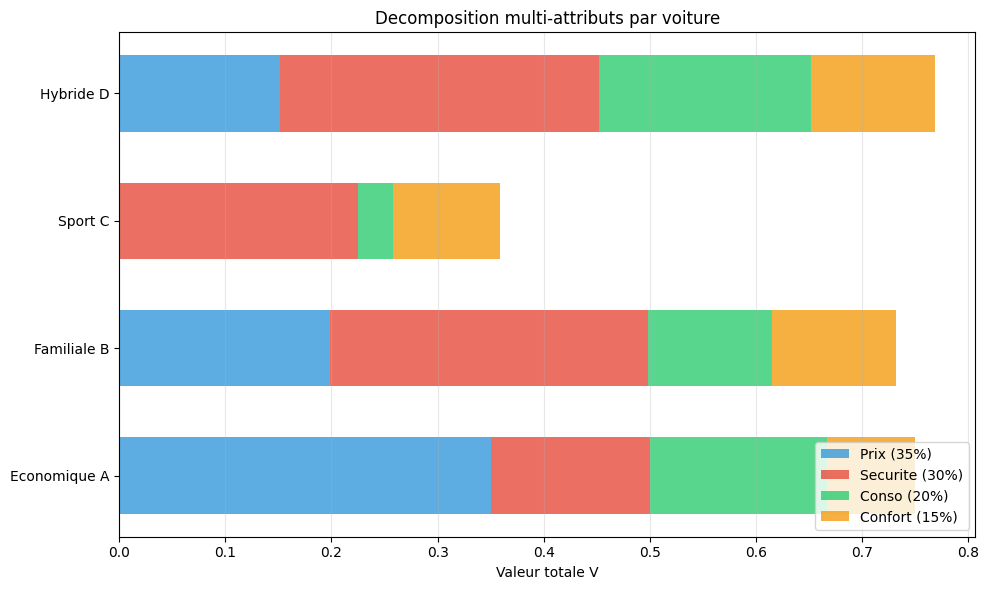

Barres empilees : chaque couleur = contribution d'un attribut a V_total.
Meilleur choix : Hybride D


In [7]:
# Visualisation bar chart stacked : decomposition par attribut
fig, ax = plt.subplots(figsize=(10, 6))

noms_voitures = [v.nom for v in voitures]
y_pos = np.arange(len(voitures))

# Valeurs par composante
components = {
    'Prix (35%)': [w_prix * v_prix(v.prix) for v in voitures],
    'Securite (30%)': [w_securite * v_securite(v.securite) for v in voitures],
    'Conso (20%)': [w_conso * v_conso(v.consommation) for v in voitures],
    'Confort (15%)': [w_confort * v_confort(v.confort) for v in voitures],
}

colors = ['#3498db', '#e74c3c', '#2ecc71', '#f39c12']
left = np.zeros(len(voitures))

for (label, values), color in zip(components.items(), colors):
    ax.barh(y_pos, values, left=left, height=0.6, label=label, color=color, alpha=0.8)
    left += values

ax.set_yticks(y_pos)
ax.set_yticklabels(noms_voitures)
ax.set_xlabel("Valeur totale V")
ax.set_title("Decomposition multi-attributs par voiture")
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig("value_decomposition.png", dpi=100, bbox_inches="tight")
plt.show()

print("Barres empilees : chaque couleur = contribution d'un attribut a V_total.")
print(f"Meilleur choix : {max(zip(voitures, left), key=lambda x: x[1])[0].nom}")

### Lecture du résultat — ce que la barre empilée ajoute au tableau

Le graphique ne contient aucune information absente du tableau précédent : les longueurs de segment sont exactement les contributions pondérées déjà imprimées. Il apporte autre chose, la **forme**.

Sur Economique A, la barre est presque entièrement d'une seule couleur : le prix porte 0,350 des 0,750 du total, soit près de la moitié du score à lui seul, et le confort n'y contribue que pour 0,083. Sur Hybride D, la barre est répartie — 0,300 de sécurité, 0,200 de consommation, 0,152 de prix, 0,117 de confort — avec un maximum à 39 % du total. Sur Sport C, la barre est courte mais **concentrée sur un seul segment** : 0,225 de ses 0,358 viennent de la sécurité, soit 63 %, et les trois autres attributs se partagent 0,133. Une voiture qui tient debout sur un attribut unique n'est pas dans la même situation qu'une voiture qui tient debout sur quatre.

C'est cette distinction qu'un total unique efface. Deux options à 0,75 peuvent être une option mono-attribut et une option équilibrée ; elles n'ont pas le même comportement quand les poids bougent, et c'est le graphique qui le rend visible d'un coup d'œil. Le tableau donne les mêmes nombres, mais il faut les comparer ligne à ligne pour voir la forme ; ici elle se voit sans lire.

Un détail de code mérite d'être signalé, parce qu'il est une bonne pratique : la dernière ligne ne réutilise pas les scores calculés plus haut, elle les **recalcule** à partir des longueurs de barres, qui sont la somme des segments effectivement dessinés. Le fait que les deux chemins donnent le même gagnant est un contrôle croisé gratuit entre le calcul et le rendu — si la fonction de tracé avait inversé deux attributs, c'est l'affichage qui l'aurait révélé.


## 5. Determination des Poids (Swing Weights)

La méthode des swing weights (cf. **von Winterfeldt & Edwards, 1986** ; **Keeney & Raiffa, 1976**) compare la **valeur des ameliorations** plutot que les attributs eux-mêmes.

> **Étapes :**

1. **Point de reference** : L'option la pire possible (tous attributs au minimum)
2. **Identifier les swings** : Pour chaque attribut, le passage du pire au meilleur niveau
3. **Classer les swings** : "Quel swing prefererais-je realiser en premier ?"
4. **Attribuer des points** : 100 points au swing le plus important, les autres proportionnellement
5. **Normaliser** : Diviser chaque score par la somme totale

In [8]:
print("Situation de depart (pire option) :\n")
print("  Prix : 45 000 EUR (maximum)")
print("  Securite : 1 etoile (minimum)")
print("  Consommation : 10 L/100km (maximum)")
print("  Confort : 1/10 (minimum)\n")

print("Classez les swings suivants par ordre de preference :\n")
print("  A) Prix : 45 000 -> 15 000 (economie de 30 000 EUR)")
print("  B) Securite : 1 -> 5 etoiles")
print("  C) Consommation : 10 -> 4 L/100km")
print("  D) Confort : 1 -> 10\n")

swing_points = {
    "Securite": 100,
    "Prix": 90,
    "Consommation": 50,
    "Confort": 40,
}

total_swing = sum(swing_points.values())
print("Points swing et poids normalises :\n")
for attr in sorted(swing_points, key=swing_points.get, reverse=True):
    poids = swing_points[attr] / total_swing
    print(f"  {attr:<12} : {swing_points[attr]:>3} points => poids = {poids:.1%}")

Situation de depart (pire option) :

  Prix : 45 000 EUR (maximum)
  Securite : 1 etoile (minimum)
  Consommation : 10 L/100km (maximum)
  Confort : 1/10 (minimum)

Classez les swings suivants par ordre de preference :

  A) Prix : 45 000 -> 15 000 (economie de 30 000 EUR)
  B) Securite : 1 -> 5 etoiles
  C) Consommation : 10 -> 4 L/100km
  D) Confort : 1 -> 10

Points swing et poids normalises :

  Securite     : 100 points => poids = 35.7%
  Prix         :  90 points => poids = 32.1%
  Consommation :  50 points => poids = 17.9%
  Confort      :  40 points => poids = 14.3%


### Lecture du résultat — la sécurité passe devant le prix

Le classement des swings donne : sécurité 100 points, prix 90, consommation 50, confort 40, soit après normalisation 35,7 %, 32,1 %, 17,9 % et 14,3 %.

Comparez ces valeurs à celles qui servent depuis la section 4 : prix 35 %, sécurité 30 %, consommation 20 %, confort 15 %. Les deux premiers rangs sont **inversés**. La procédure par swings, qui interroge le décideur sur des passages concrets du pire au meilleur, place la sécurité en tête ; les poids de travail plaçaient le prix en tête.

Ce n'est pas un détail d'affichage : cela change l'identité du deuxième. Avec les poids de travail, Hybride D l'emporte à 0,768 et Economique A suit à 0,750, soit 0,018 d'écart, en vertu de son seul prix. Avec les poids issus des swings, D monte à 0,786 et c'est **Familiale B** qui prend la deuxième place à 0,755 : Economique A retombe à 0,728, troisième. Le vainqueur ne change pas, le podium si, et l'écart qui sépare le premier du deuxième passe de 0,018 à 0,031.

L'enseignement est double. Un poids n'est pas une propriété de l'attribut mais **une réponse à une question précise** — « combien vaut le passage du pire au meilleur sur cet attribut ? » — et changer la question change la réponse. Et la procédure par swings a un mérite que des poids posés à la main n'ont pas : elle oblige à comparer des écarts réels sur une échelle commune, au lieu de répartir cent pour cent d'autorité entre quatre colonnes. Répartir cent pour cent est une opération arithmétique ; comparer des écarts est un jugement, et c'est le jugement que la méthode veut recueillir.


### Exercice 2 : Swing Weights pour un Choix d'Appartement

Vous cherchez un appartement parmi 4 options, evaluees sur 4 attributs : Prix (EUR/mois), Surface (m2), Quartier (note 1-10), Trajet travail (minutes). Aucun appartement ne domine sur tous les critères.

**Objectif** : Appliquer la méthode des swing weights pour determiner les poids, puis calculer V_total pour classer les appartements.

**Étapes** :
1. Définir les niveaux pire/meilleur pour chaque attribut
2. Classer les swings du plus au moins important
3. Attribuer 100 points au swing le plus important, les autres proportionnellement
4. Normaliser les scores pour obtenir les poids w_i
5. Calculer V = sum(w_i * v_i) pour chaque appartement

**Indices** :
- **Indice** 1 : Pour le Prix et le Trajet, "moins = mieux" (inverser la normalisation)
- **Indice** 2 : Le swing "Prix : 1200 -> 600" economise 600 EUR/mois -- est-ce plus important que "Surface : 20 -> 65 m2" ?
- **Indice** 3 : Normalisation : v_i(x) = (x - pire) / (meilleur - pire), inverser si sens = min

In [9]:
# Exercice 2 : Swing Weights pour un Choix d'Appartement
# TODO étudiant : appliquer la méthode des swing weights et classer les appartements

# Étape 1 : Définir les 4 appartements
appartements = [
    {"nom": "Studio Centre",    "prix": 950,  "surface": 25, "quartier": 8, "trajet": 10},
    {"nom": "T2 Banlieue",      "prix": 650,  "surface": 45, "quartier": 5, "trajet": 45},
    {"nom": "T3 Peripherie",    "prix": 800,  "surface": 65, "quartier": 6, "trajet": 30},
    {"nom": "Coloc Campus",     "prix": 450,  "surface": 20, "quartier": 7, "trajet": 5},
]

# Étape 2 : Définir les niveaux pire et meilleur pour chaque attribut
# TODO étudiant : identifier les bornes à partir des données ci-dessus
# prix : min=?, max=? (sens = min)
# surface : min=?, max=? (sens = max)
# quartier : min=?, max=? (sens = max)
# trajet : min=?, max=? (sens = min)

# Étape 3 : Classer les swings et attribuer des points
# TODO étudiant : quel swing est le plus important ? Attribuer 100 points au premier, puis proportionnellement.

# Étape 4 : Normaliser pour obtenir les poids
# TODO étudiant : w_i = points_i / sum(points)

# Étape 5 : Calculer V_total pour chaque appartement
# TODO étudiant : normaliser chaque attribut, pondérer, sommer

result = None  # TODO étudiant : remplacer par le classement final
print("Exercice a completer : swing weights et classement des appartements.")

Exercice a completer : swing weights et classement des appartements.


## 6. Utilite Multiplicative pour les Loteries

### Quand la forme additive ne suffit plus

Quand les outcomes sont **incertains**, la forme additive suppose que l'aversion au risque est la même quel que soit le niveau des autres attributs.

### Forme multiplicative (Keeney-Raiffa)

Introduite par **Keeney & Raiffa (1976)**, cette forme ajoute un facteur d'echelle $k$ qui capture les interactions entre attributs lorsque les issues sont incertaines.

$$1 + kU(x_1, x_2) = [1 + kk_1U_1(x_1)][1 + kk_2U_2(x_2)]$$

| Valeur de k | Interpretation |
|-------------|----------------|
| k = 0 | Forme additive (pas d'interaction) |
| k > 0 | Synergies : avoir les deux attributs eleves vaut plus que la somme |
| k < 0 | Substituts : ameliorer un attribut reduit l'importance de l'autre |

In [10]:
class MultiplicativeUtility:
    """Utilite multi-attributs multiplicative (Keeney & Raiffa, 1976)."""

    def __init__(self, weights):
        self.k = np.array(weights)
        self.K = self._find_K()

    def _find_K(self):
        """Trouve K tel que prod(1 + K*ki) = 1 + K par bissection bornee.

        On borne la recherche au domaine valide K in (-1/max(ki), 0) quand
        sum(ki) > 1, et K > 0 quand sum(ki) < 1, afin de garantir 1 + K*ki > 0
        pour tout i (condition necessaire a l'interpretation en termes
        d'utilite). Une bissection bornee evite qu'un Newton-Raphson non
        contraint ne diverge vers une racine numeriquement artefactuelle
        (|K| > 1/max(ki)) qui violerait cette condition."""
        sum_k = self.k.sum()
        if abs(sum_k - 1) < 1e-6:
            return 0.0

        def f(K):
            return np.prod(1 + K * self.k) - 1 - K

        if sum_k > 1:
            lo, hi = -1.0 / max(self.k) + 1e-9, -1e-9
        else:
            lo, hi = 1e-9, 1e9
        for _ in range(200):
            mid = 0.5 * (lo + hi)
            if abs(f(mid)) < 1e-12 or (hi - lo) < 1e-12:
                return mid
            if np.sign(f(mid)) == np.sign(f(lo)):
                lo = mid
            else:
                hi = mid
        return 0.5 * (lo + hi)

    def compute(self, u_values):
        u_values = np.asarray(u_values)
        if abs(self.K) < 1e-10:
            return np.dot(self.k, u_values)
        prod = np.prod(1 + self.K * self.k * u_values)
        return (prod - 1) / self.K


# Exemple avec 3 attributs (sum > 1 => K != 0)
mu = MultiplicativeUtility([0.4, 0.35, 0.35])
print(f"Poids : k1=0.4, k2=0.35, k3=0.35 (sum = 1.1)")
print(f"Facteur K calcule : {mu.K:.4f}\n")

scenarios = {
    "u = (1,1,1)": [1.0, 1.0, 1.0],
    "u = (1,0.5,0.5)": [1.0, 0.5, 0.5],
    "u = (0.5,0.5,0.5)": [0.5, 0.5, 0.5],
}
for name, vals in scenarios.items():
    print(f"  {name} : U_mult = {mu.compute(vals):.3f}")

Poids : k1=0.4, k2=0.35, k3=0.35 (sum = 1.1)
Facteur K calcule : -0.2565

  u = (1,1,1) : U_mult = 1.000
  u = (1,0.5,0.5) : U_mult = 0.707
  u = (0.5,0.5,0.5) : U_mult = 0.525


Comparaison des deux formes d'utilite sur les mêmes données.

In [11]:
# Comparaison des trois regimes : substituables (K < 0), additif (K = 0), complements (K > 0)
#
# Avec w1 = w2 = 0.5, la somme des poids vaut exactement 1 et _find_K() retourne K = 0 :
# la forme multiplicative se reduit ALORS a la forme additive, et la comparaison ne
# montre rien. Le regime se choisit en faisant varier la somme des poids.
modeles_cmp = [
    ("Substituables  w=[0.6, 0.6]", MultiplicativeUtility([0.6, 0.6])),
    ("Additif        w=[0.5, 0.5]", MultiplicativeUtility([0.5, 0.5])),
    ("Complements    w=[0.4, 0.4]", MultiplicativeUtility([0.4, 0.4])),
]

for titre, modele in modeles_cmp:
    print(f"{titre}  ->  K = {modele.K:+.4f}")

scenarios_cmp = [
    ("Bon X, mauvais Y", 0.9, 0.2),
    ("Mauvais X, bon Y", 0.2, 0.9),
    ("Mediocre partout", 0.5, 0.5),
    ("Excellent partout", 0.9, 0.9),
]

mu_sub = modeles_cmp[0][1]
mu_com = modeles_cmp[2][1]

print()
print(f"{'Scenario':<22} | {'Additif':>7} | {'K<0':>7} | {'K>0':>7} | {'Ecart K<0':>9} | {'Ecart K>0':>9}")
print("-" * 22 + "-+-" + "-" * 7 + "-+-" + "-" * 7 + "-+-" + "-" * 7 + "-+-" + "-" * 9 + "-+-" + "-" * 9)

for nom, v1, v2 in scenarios_cmp:
    u_add = 0.5 * v1 + 0.5 * v2
    u_sub = mu_sub.compute([v1, v2])
    u_com = mu_com.compute([v1, v2])
    print(f"{nom:<22} | {u_add:>7.3f} | {u_sub:>7.3f} | {u_com:>7.3f} | {u_sub - u_add:>+9.3f} | {u_com - u_add:>+9.3f}")

print()
for titre, modele in modeles_cmp:
    if modele.K < -1e-9:
        print(f"{titre} : K < 0 -> attributs SUBSTITUTS, la forme multiplicative")
        print("    surestime les profils mixtes (un bon compense un mauvais)")
    elif modele.K > 1e-9:
        print(f"{titre} : K > 0 -> attributs COMPLEMENTS, la forme multiplicative")
        print("    sous-estime les profils mixtes (un mauvais penalise le bon)")
    else:
        print(f"{titre} : K = 0 -> aucune interaction, la forme multiplicative")
        print("    EST la forme additive")


Substituables  w=[0.6, 0.6]  ->  K = -0.5556
Additif        w=[0.5, 0.5]  ->  K = +0.0000
Complements    w=[0.4, 0.4]  ->  K = +1.2500

Scenario               | Additif |     K<0 |     K>0 | Ecart K<0 | Ecart K>0
-----------------------+---------+---------+---------+-----------+----------
Bon X, mauvais Y       |   0.550 |   0.624 |   0.476 |    +0.074 |    -0.074
Mauvais X, bon Y       |   0.550 |   0.624 |   0.476 |    +0.074 |    -0.074
Mediocre partout       |   0.500 |   0.550 |   0.450 |    +0.050 |    -0.050
Excellent partout      |   0.900 |   0.918 |   0.882 |    +0.018 |    -0.018

Substituables  w=[0.6, 0.6] : K < 0 -> attributs SUBSTITUTS, la forme multiplicative
    surestime les profils mixtes (un bon compense un mauvais)
Additif        w=[0.5, 0.5] : K = 0 -> aucune interaction, la forme multiplicative
    EST la forme additive
Complements    w=[0.4, 0.4] : K > 0 -> attributs COMPLEMENTS, la forme multiplicative
    sous-estime les profils mixtes (un mauvais penalise le 

### Lecture du résultat — ce que fait vraiment le facteur K

Trois régimes, trois comportements, et un seul paramètre les sépare. Avec des poids dont la somme vaut 0,8, la bissection rend K = +1,2500 : les attributs sont **compléments**, un mauvais attribut pénalise le bon, et la forme multiplicative place tous les profils sous leur équivalent additif. Avec une somme de 1,2, elle rend K = −0,5556 : les attributs sont **substituables**, un bon en compense un mauvais, et tous les profils passent au-dessus. Avec une somme de 1, la fonction retourne K = 0 par construction, et les deux formes coïncident — la comparaison ne démontre alors rien, quel que soit le nombre de scénarios alignés.

Les écarts mesurés valent ±0,074 sur les deux profils mixtes, ±0,050 sur le profil médiocre et ±0,018 sur le profil excellent : les mêmes valeurs au signe près de part et d'autre du régime additif. Ce n'est pas une coïncidence d'arrondi. Les deux jeux de poids sont symétriques autour de 1 et le décalage l'est aussi, ce qui donne à ce tableau une valeur de contrôle : si les deux colonnes d'écart n'étaient pas symétriques, c'est la fonction de recherche de K qu'il faudrait suspecter, pas l'interprétation.

Deux choses s'en déduisent. D'abord, l'interaction entre attributs ne se lit pas dans l'écart d'un scénario isolé mais dans son **signe et son amplitude relative** : les profils extrêmes sont peu affectés, 0,018 sur 0,900 soit deux pour cent, là où les profils mixtes bougent de treize pour cent. Ensuite, K n'est pas un paramètre qu'on choisit librement : il est **entièrement déterminé** par les poids dès que l'on impose les conditions de cohérence de Keeney-Raiffa. Une élicitation qui fixe les poids fixe donc aussi le degré de substituabilité, et c'est ce qu'il faut savoir avant de lire un score multiplicatif comme une simple moyenne pondérée. Le cas K = 0 n'est pas un cas parmi d'autres : c'est le seul où la distinction entre les deux formes disparaît, et c'est précisément celui que la version précédente de ce carnet exhibait.


### Exercice 3 : Forme Multiplicative pour un Choix d'Investissement

Trois options d'investissement sont evaluees sur trois critères : rendement espere, risque (inverse) et liquidite. Contrairement a la forme additive, la forme multiplicative de Keeney-Raiffa capture les interactions entre attributs.

**Objectif** : Appliquer la forme multiplicative et comparer avec la forme additive.

**Indices** :
- **Étape** 1 : Définir les 3 investissements avec leurs utilites marginales u_rend, u_risque, u_liquidite (entre 0 et 1)
- **Étape** 2 : Créer une instance de `MultiplicativeUtility` avec les poids {0.4, 0.35, 0.25} (notez que la somme > 1)
- **Étape** 3 : Calculer U_mult et U_add pour chaque investissement
- **Étape** 4 : Verifier si le classement change entre les deux formes

In [12]:
# Exercice 3 : Forme Multiplicative pour un Choix d'Investissement
# TODO étudiant : appliquer la forme multiplicative et comparer avec la forme additive

# Étape 1 : Définir les 3 investissements avec utilités marginales (0-1)
investissements = None  # TODO étudiant : liste de dicts, ex: [{"nom": "Obligations", "u_rend": 0.3, "u_risque": 0.8, "u_liquidite": 0.9}, ...]

# Étape 2 : Créer une instance de MultiplicativeUtility avec poids [0.4, 0.35, 0.25]
mu_inv = None  # TODO étudiant : MultiplicativeUtility([0.4, 0.35, 0.25])

# Étape 3 : Calculer U_mult et U_add pour chaque investissement
# Indice : U_add = 0.4 * u_rend + 0.35 * u_risque + 0.25 * u_liquidite
# Indice : U_mult = mu_inv.compute([u_rend, u_risque, u_liquidite])

# Étape 4 : Afficher le classement comparatif
result = None  # TODO étudiant : remplacer par le tableau des resultats

print("Exercice a completer : forme multiplicative pour choix d'investissement.")

Exercice a completer : forme multiplicative pour choix d'investissement.


## 7. Méthode SMART

### Simple Multi-Attribute Rating Technique

SMART (**Edwards, 1971, 1977**) est une méthode pratique en 7 étapes, raffinee en SMARTS puis SMARTER par **Edwards & Barron (1994)** :

1. **Identifier** les attributs pertinents
2. **Définir** les echelles pour chaque attribut
3. **Classer** les attributs par importance
4. **Ponderer** par la méthode des swings
5. **Evaluer** chaque alternative sur chaque attribut
6. **Normaliser** les evaluations (0-1)
7. **Calculer** la valeur totale : $V = \sum w_i \times v_i$

In [13]:
@dataclass
class CareerOption:
    name: str
    salary: float      # k EUR/an
    work_life: int     # 1-10
    passion: int       # 1-10
    job_security: int  # 1-10

careers = [
    CareerOption("Startup", 45, 3, 9, 4),
    CareerOption("Grande Entreprise", 55, 6, 5, 8),
    CareerOption("Fonction Publique", 38, 8, 4, 10),
    CareerOption("Freelance", 60, 5, 8, 3),
    CareerOption("Recherche", 35, 7, 10, 6),
]

weights_smart = {"salary": 0.30, "work_life": 0.25, "passion": 0.25, "job_security": 0.20}

sal_min = min(c.salary for c in careers)
sal_max = max(c.salary for c in careers)
norm_sal = lambda s: (s - sal_min) / (sal_max - sal_min)
norm_10 = lambda x: (x - 1) / 9.0

print("=== SMART : Choix de Carriere ===")
print(f"Poids : Salaire={weights_smart['salary']:.0%}, Equilibre={weights_smart['work_life']:.0%}, ")
print(f"        Passion={weights_smart['passion']:.0%}, Securite={weights_smart['job_security']:.0%}\n")

print(f"{'Carriere':<20} | {'v_sal':>5} | {'v_wlb':>5} | {'v_pas':>5} | {'v_sec':>5} | {'V':>6}")
print("-" * 20 + "-+-" + "-" * 5 + "-+-" + "-" * 5 + "-+-" + "-" * 5 + "-+-" + "-" * 5 + "-+-" + "-" * 6)

for c in careers:
    v_sal = norm_sal(c.salary)
    v_wlb = norm_10(c.work_life)
    v_pas = norm_10(c.passion)
    v_sec = norm_10(c.job_security)
    V = (weights_smart["salary"] * v_sal + weights_smart["work_life"] * v_wlb +
         weights_smart["passion"] * v_pas + weights_smart["job_security"] * v_sec)
    print(f"{c.name:<20} | {v_sal:>5.3f} | {v_wlb:>5.3f} | {v_pas:>5.3f} | {v_sec:>5.3f} | {V:>6.3f}")

best = max(careers, key=lambda c: (
    weights_smart["salary"] * norm_sal(c.salary) + weights_smart["work_life"] * norm_10(c.work_life) +
    weights_smart["passion"] * norm_10(c.passion) + weights_smart["job_security"] * norm_10(c.job_security)
))
print(f"\n=> Meilleur choix avec ces poids : {best.name}")

=== SMART : Choix de Carriere ===
Poids : Salaire=30%, Equilibre=25%, 
        Passion=25%, Securite=20%

Carriere             | v_sal | v_wlb | v_pas | v_sec |      V
---------------------+-------+-------+-------+-------+-------
Startup              | 0.400 | 0.222 | 0.889 | 0.333 |  0.464
Grande Entreprise    | 0.800 | 0.556 | 0.444 | 0.778 |  0.646
Fonction Publique    | 0.120 | 0.778 | 0.333 | 1.000 |  0.514
Freelance            | 1.000 | 0.444 | 0.778 | 0.222 |  0.650
Recherche            | 0.000 | 0.667 | 1.000 | 0.556 |  0.528

=> Meilleur choix avec ces poids : Freelance


Profils de carriere : comparaison multi-attributs avec les poids SMART.

In [14]:
print("Profils de carriere - Comparaison multi-attributs :\n")
print(f"{'Carriere':<20} | {'Salaire':>7} | {'Equilibre':>9} | {'Passion':>7} | {'Securite':>9} | {'Score':>5}")
print("-" * 20 + "-+-" + "-" * 7 + "-+-" + "-" * 9 + "-+-" + "-" * 7 + "-+-" + "-" * 9 + "-+-" + "-" * 5)

for c in careers:
    vSal = norm_sal(c.salary)
    vWlb = norm_10(c.work_life)
    vPas = norm_10(c.passion)
    vSec = norm_10(c.job_security)
    score = (weights_smart["salary"] * vSal + weights_smart["work_life"] * vWlb +
             weights_smart["passion"] * vPas + weights_smart["job_security"] * vSec)
    print(f"{c.name:<20} | {vSal:>7.2f} | {vWlb:>9.2f} | {vPas:>7.2f} | {vSec:>9.2f} | {score:>5.3f}")

print(f"\nPoids : Salaire={weights_smart['salary']:.0%}, Equilibre={weights_smart['work_life']:.0%}, "
      f"Passion={weights_smart['passion']:.0%}, Securite={weights_smart['job_security']:.0%}")

Profils de carriere - Comparaison multi-attributs :

Carriere             | Salaire | Equilibre | Passion |  Securite | Score
---------------------+---------+-----------+---------+-----------+------
Startup              |    0.40 |      0.22 |    0.89 |      0.33 | 0.464
Grande Entreprise    |    0.80 |      0.56 |    0.44 |      0.78 | 0.646
Fonction Publique    |    0.12 |      0.78 |    0.33 |      1.00 | 0.514
Freelance            |    1.00 |      0.44 |    0.78 |      0.22 | 0.650
Recherche            |    0.00 |      0.67 |    1.00 |      0.56 | 0.528

Poids : Salaire=30%, Equilibre=25%, Passion=25%, Securite=20%


### Lecture du résultat — quatre millièmes entre les deux premiers

Freelance l'emporte avec 0,650, devant Grande Entreprise à 0,646 : quatre millièmes. Le classement est donc, à cette résolution, une égalité. Deux observations rendent ce résultat plus fragile encore qu'il n'y paraît.

**Les échelles de normalisation ne se ressemblent pas.** Le salaire est ramené par un min-max calculé sur les seules cinq carrières présentes : Recherche, à 35 k, vaut 0,000, et Freelance, à 60 k, vaut 1,000. Cet attribut utilise donc toute la plage. Les trois attributs notés de 1 à 10 sont ramenés par (x − 1)/9, qui suppose qu'un 1 et un 10 existent dans les données — ce qui n'est pas le cas. L'équilibre vie-travail va de 3 à 8, donc de 0,222 à 0,778 : il n'occupe que 56 % de son échelle. La sécurité va de 3 à 10, la passion de 4 à 10.

**Conséquence directe sur les poids.** Un poids de 25 % sur l'équilibre vie-travail ne peut produire au mieux qu'une contribution de 25 % × 0,778 = 0,194, quand le salaire, à 30 %, peut atteindre 0,300. L'attribut que le récit présente comme central pèse donc, en pratique, un tiers de moins que son poids affiché. Ce n'est pas une erreur de calcul : c'est l'effet d'une normalisation par des bornes théoriques sur des données qui n'occupent pas ces bornes.

La leçon vaut bien au-delà de ce jeu de données : avant de comparer des scores pondérés, vérifier **l'amplitude réellement occupée** par chaque attribut normalisé. Deux attributs de même poids ne contribuent pas de la même façon si l'un s'étale sur toute sa plage et l'autre sur la moitié. Et une normalisation min-max calculée sur l'échantillon, comme celle du salaire, rend les scores incomparables d'un jeu de données à un autre puisque ses bornes changent avec les données.


## 8. Analyse de Sensibilite

Les poids sont souvent incertains. L'analyse de sensibilite montre comment le choix change quand on fait varier les poids.

In [15]:
print("Analyse de sensibilite : poids du Salaire\n")
print(f"{'w_salaire':>10} | {'Meilleur choix':<20} | {'V_meilleur':>10}")
print("-" * 10 + "-+-" + "-" * 20 + "-+-" + "-" * 10)

for w_sal in np.arange(0.1, 0.55, 0.1):
    remaining = 1 - w_sal
    w_wlb = 0.25 / 0.70 * remaining
    w_pas = 0.25 / 0.70 * remaining
    w_sec = 0.20 / 0.70 * remaining

    def score(c):
        return (w_sal * norm_sal(c.salary) + w_wlb * norm_10(c.work_life) +
                w_pas * norm_10(c.passion) + w_sec * norm_10(c.job_security))

    best_opt = max(careers, key=score)
    print(f"{w_sal:>10.0%} | {best_opt.name:<20} | {score(best_opt):>10.3f}")

print("\n=> Le choix optimal change selon l'importance accordee au salaire.")

Analyse de sensibilite : poids du Salaire

 w_salaire | Meilleur choix       | V_meilleur
-----------+----------------------+-----------
       10% | Recherche            |      0.679
       20% | Grande Entreprise    |      0.623
       30% | Freelance            |      0.650
       40% | Freelance            |      0.700
       50% | Freelance            |      0.750

=> Le choix optimal change selon l'importance accordee au salaire.


### Exercice 4 : Analyse de sensibilite multi-poids

On veut verifier la robustesse du choix SMART en faisant varier **simultanement** deux poids.

**Objectif** : Faire varier `w_salaire` de 10% a 50% et `w_passion` de 10% a 40% (les autres poids s'ajustent proportionnellement). Pour chaque couple, identifier la meilleure carriere.

**Indices** :
- **Étape** 1 : Fixer `w_salaire` et `w_passion`, les autres poids se partagent le reste : `remaining = 1 - w_sal - w_pas`
- **Étape** 2 : `w_wlb = 0.25 / 0.45 * remaining` et `w_sec = 0.20 / 0.45 * remaining`
- **Étape** 3 : Pour chaque couple, calculer le score de chaque carriere et identifier la meilleure

In [16]:
# Exercice 4 : Analyse de sensibilité multi-poids
# TODO étudiant : faire varier w_salaire (10%-50%) et w_passion (10%-40%) simultanément

# À compléter : boucles imbriquées sur w_salaire et w_passion
# Indice 1 : for w_sal in [0.10, 0.20, 0.30, 0.40, 0.50]:
# Indice 2 :     for w_pas in [0.10, 0.20, 0.30, 0.40]:
# Indice 3 :         remaining = 1 - w_sal - w_pas
#                 w_wlb = 0.25 / 0.45 * remaining
#                 w_sec = 0.20 / 0.45 * remaining

# À compléter : pour chaque couple (w_sal, w_pas), calculer le score de chaque carrière
# À compléter : afficher le meilleur choix dans un tableau (w_sal x w_pas)

result = None  # TODO étudiant : remplacer par le tableau des resultats
print("Exercice a completer : analyse de sensibilite multi-poids.")

Exercice a completer : analyse de sensibilite multi-poids.


Visualisation des courbes de sensibilite pour chaque carriere.

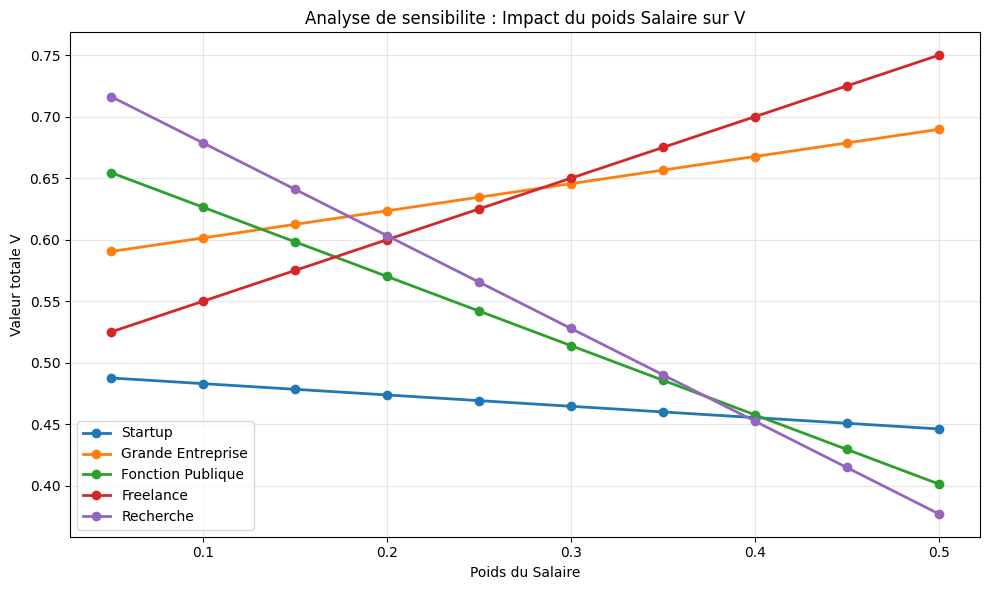

Les croisements indiquent des 'points de basculement'.
Freelance domine pour w_salaire > 25%. Recherche domine pour w_salaire < 15%.


In [17]:
w_salary_range = np.arange(0.05, 0.55, 0.05)

fig, ax = plt.subplots(figsize=(10, 6))

for c in careers:
    V_values = []
    for w_sal in w_salary_range:
        remaining = 1 - w_sal
        w_wlb = 0.25 / 0.70 * remaining
        w_pas = 0.25 / 0.70 * remaining
        w_sec = 0.20 / 0.70 * remaining
        V = (w_sal * norm_sal(c.salary) + w_wlb * norm_10(c.work_life) +
             w_pas * norm_10(c.passion) + w_sec * norm_10(c.job_security))
        V_values.append(V)
    ax.plot(w_salary_range, V_values, marker='o', linewidth=2, label=c.name)

ax.set_xlabel("Poids du Salaire")
ax.set_ylabel("Valeur totale V")
ax.set_title("Analyse de sensibilite : Impact du poids Salaire sur V")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("sensitivity_analysis.png", dpi=100, bbox_inches="tight")
plt.show()

print("Les croisements indiquent des 'points de basculement'.")
print("Freelance domine pour w_salaire > 25%. Recherche domine pour w_salaire < 15%.")

### Interpretation : la robustesse d'une recommandation MAUT

Les courbes de sensibilité transforment la recommandation MAUT — un **point** (un classement pour des poids fixés) — en une **fonction** : comment le classement évolue quand on perturbe les poids. C'est le complément indispensable du calcul de valeur, et sa lecture se fait sur deux plans.

**Les croisements sont des points de bascule.** Là où deux courbes se croisent, l'option optimale **change**. Ici, le Freelance domine tant que le poids du salaire dépasse ~25 %, et la Recherche domine en dessous de ~15 %. Entre les deux, plusieurs carrières restent compétitives : la recommandation n'est plus tranchée. Un classement MAUT donné sans cette analyse de sensibilité laisse croire que le vainqueur est robuste alors qu'il peut ne tenir qu'à un poids mal élucidé.

**Implication pour la décision.** Si le poids du salaire est bien élucidé (loin de la bande ambiguë 15–25 %), la recommandation est **stable** et on peut décider en confiance. S'il tombe dans la bande de bascule, deux attitudes cohérentes : (a) **élucider plus finement** la prérence sur le salaire (swing weight, trade-off direct) pour quitter la zone d'ambiguïté ; (b) **accepter que la décision est sensible au poids** et introduire un critère discriminant supplémentaire ou un principe de précaution (privilégier l'option la plus robuste, pas la mieux classée en moyenne).

C'est la leçon méthodologique : l'analyse de sensibilité ne raffine pas la recommandation, elle **quantifie la confiance** qu'on peut lui accorder. Une recommandation MAUT sans sensibilité est un avis ; avec, c'est un avis accompagné de son domaine de validité.


## 9. Decision sous Incertitude avec Monte Carlo

### Scénario avec incertitude

Si les attributs sont incertains, on modelise leurs distributions et on calcule l'utilite esperee par integration Monte Carlo.

Distributions des attributs :
  Projet A : Rendement ~ N(0.08, 0.01), Risque ~ N(0.15, 0.005)
  Projet B : Rendement ~ N(0.12, 0.02), Risque ~ N(0.25, 0.01)

E[U(Projet A)] = 0.5091 (std = 0.2244)
E[U(Projet B)] = 0.4819 (std = 0.2567)

=> Decision optimale : Projet A


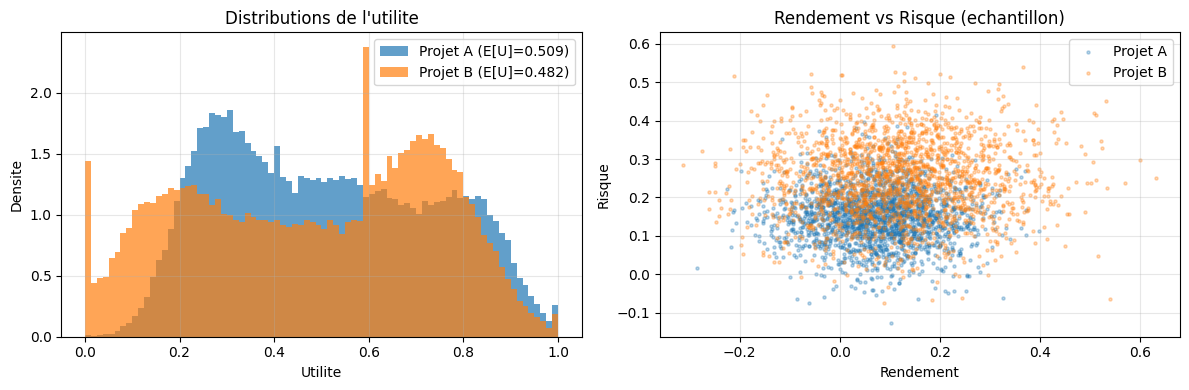

In [18]:
# Decision multi-attributs avec incertitude
# Projet A : Rendement modere, risque modere
# Projet B : Rendement eleve, risque eleve

N_mc = 50000
rng_mc = np.random.default_rng(RANDOM_SEED)

# Distributions des attributs (Gaussiennes)
rend_A = rng_mc.normal(0.08, np.sqrt(0.01), N_mc)
risque_A = rng_mc.normal(0.15, np.sqrt(0.005), N_mc)
rend_B = rng_mc.normal(0.12, np.sqrt(0.02), N_mc)
risque_B = rng_mc.normal(0.25, np.sqrt(0.01), N_mc)

print("Distributions des attributs :")
print(f"  Projet A : Rendement ~ N(0.08, 0.01), Risque ~ N(0.15, 0.005)")
print(f"  Projet B : Rendement ~ N(0.12, 0.02), Risque ~ N(0.25, 0.01)\n")

# Fonction d'utilité multi-attributs
w_rend = 0.6
w_risque = 0.4
v_rend = lambda r: np.clip(r / 0.20, 0, 1)
v_risque = lambda r: 1 - np.clip(r / 0.40, 0, 1)

U_A = w_rend * v_rend(rend_A) + w_risque * v_risque(risque_A)
U_B = w_rend * v_rend(rend_B) + w_risque * v_risque(risque_B)

EU_A = U_A.mean()
EU_B = U_B.mean()

print(f"E[U(Projet A)] = {EU_A:.4f} (std = {U_A.std():.4f})")
print(f"E[U(Projet B)] = {EU_B:.4f} (std = {U_B.std():.4f})")
print(f"\n=> Decision optimale : {'Projet A' if EU_A > EU_B else 'Projet B'}")

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(U_A, bins=80, alpha=0.7, label=f'Projet A (E[U]={EU_A:.3f})', density=True)
axes[0].hist(U_B, bins=80, alpha=0.7, label=f'Projet B (E[U]={EU_B:.3f})', density=True)
axes[0].set_xlabel("Utilite")
axes[0].set_ylabel("Densite")
axes[0].set_title("Distributions de l'utilite")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].scatter(rend_A[:2000], risque_A[:2000], alpha=0.3, s=5, label='Projet A')
axes[1].scatter(rend_B[:2000], risque_B[:2000], alpha=0.3, s=5, label='Projet B')
axes[1].set_xlabel("Rendement")
axes[1].set_ylabel("Risque")
axes[1].set_title("Rendement vs Risque (echantillon)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("investment_decision.png", dpi=100, bbox_inches="tight")
plt.show()

### Interpretation : Arbitrage rendement-risque

Le projet B a un meilleur rendement espere, mais son risque eleve fait basculer la decision en faveur de A. C'est l'**arbitrage rendement-risque** classique en finance.

La fonction d'utilite multi-attributs reellement calculee par le code de la section 9 -- marginales **saturees** sur $[0, 1]$ :

$$U(\text{rend}, \text{risque}) = 0.6 \times \mathrm{clip}\left(\tfrac{\text{rend}}{0.20},\, 0,\, 1\right) + 0.4 \times \left(1 - \mathrm{clip}\left(\tfrac{\text{risque}}{0.40},\, 0,\, 1\right)\right)$$

La saturation n'est pas un detail d'implementation : sans elle (formule lineaire non bornee), l'esperance exacte donne $E[U(A)] = 0{,}49 < E[U(B)] = 0{,}51$ et la recommandation s'inverse -- les deux contrats ne decrivent pas le même decideur.

**Hypothese d'additivite sous loteries.** Le theoreme de Debreu-Gorman (section 4) justifie la forme additive pour des consequences **certaines**. L'etendre a l'utilite esperee sur des **loteries** demande une hypothese plus forte : l'indépendance additive (cas $k = 0$ de la forme multiplicative de Keeney-Raiffa, section 6) -- chaque $v_i$ garde sa forme quel que soit le niveau des autres attributs. La section 9 tient cette hypothese ; le contre-exemple suivant montre qu'elle est une hypothese a part entiere, pas un corollaire de l'indépendance preferentielle.


### Pourquoi l'additivite sous loteries est une hypothese a part

Deux proprietes sont souvent confondues :

- **Indépendance preferentielle (consequences certaines)** : le classement de deux niveaux d'un attribut ne depend pas des niveaux des autres. Elle fonde la forme additive de la fonction de valeur $V$ (Debreu-Gorman, section 4).
- **Indépendance additive (loteries)** : pour des issues incertaines, $E[U]$ ne se decompose en $\sum_i w_i\, E[v_i]$ que si chaque $v_i$ garde sa forme quel que soit le niveau des autres attributs -- le cas $k = 0$ de Keeney-Raiffa (section 6).

Le contre-exemple executable ci-dessous les separe : deux loteries aux **mêmes distributions marginales**, declarees indifferentes par toute utilite esperee additive marginale, mais separees par la vraie utilite vNM du decideur. La cellule verifie ensuite, par quadrature déterministe, le choix A/B de la section 9 sous le contrat sature retenu.


In [19]:
# Contre-exemple : l'additivite sous loteries n'est PAS un corollaire de
# l'independance preferentielle. U_vNM ci-dessous est strictement croissante
# en chaque attribut (donc preferentiellement independante), mais non additive.
U_vNM = lambda x, y, z: ((1 + x) * (1 + y) * (1 + z) - 1) / 7

# Deux loteries equiprobables aux MEMES distributions marginales :
# chaque attribut vaut 0 ou 1 avec probabilite 1/2 dans les deux cas.
L1 = [(0, 0, 0), (1, 1, 0)]
L2 = [(1, 0, 0), (0, 1, 0)]

EU_L1 = np.mean([U_vNM(*o) for o in L1])
EU_L2 = np.mean([U_vNM(*o) for o in L2])

# Toute utilite esperee additive marginale ecrit E[U] = sum_i w_i E[v_i] :
# les esperances marginales E[v_i] sont identiques pour L1 et L2, donc elle
# declare L1 et L2 indifferentes. La vraie utilite vNM les separe :
print(f"E[U_vNM(L1)] = {EU_L1:.6f}   (= 3/14 = {3/14:.6f})")
print(f"E[U_vNM(L2)] = {EU_L2:.6f}   (= 1/7  = {1/7:.6f})")
print(f"Ecart exact   = {EU_L1 - EU_L2:.6f}   (= 1/14 = {1/14:.6f})")
assert abs(EU_L1 - 3 / 14) < 1e-12 and abs(EU_L2 - 1 / 7) < 1e-12
print("=> Memes marginales, preferences differentes : l'additivite sous")
print("   loteries est une HYPOTHESE (k = 0 chez Keeney-Raiffa), pas un")
print("   corollaire de l'independance preferentielle.")

# Verification independante du choix de la section 9 sous le contrat SATURE :
# quadrature deterministe des esperances clippees (aucun Monte Carlo).
from scipy import integrate, stats

def EU_saturee(mu_rend, var_rend, mu_risque, var_risque,
               w_rend=0.6, w_risque=0.4):
    v_rend = integrate.quad(
        lambda r: np.clip(r / 0.20, 0, 1) * stats.norm.pdf(r, mu_rend, np.sqrt(var_rend)),
        -1.0, 1.0, limit=200)[0]
    v_risque = integrate.quad(
        lambda k: (1 - np.clip(k / 0.40, 0, 1)) * stats.norm.pdf(k, mu_risque, np.sqrt(var_risque)),
        -1.0, 1.0, limit=200)[0]
    return w_rend * v_rend + w_risque * v_risque

EU_A_q = EU_saturee(0.08, 0.01, 0.15, 0.005)
EU_B_q = EU_saturee(0.12, 0.02, 0.25, 0.01)
print(f"\nQuadrature deterministe : E[U(A)] = {EU_A_q:.4f}, E[U(B)] = {EU_B_q:.4f}")
print(f"Monte Carlo section 9   : E[U(A)] = {EU_A:.4f}, E[U(B)] = {EU_B:.4f}")
assert abs(EU_A_q - EU_A) < 3e-3 and abs(EU_B_q - EU_B) < 3e-3, \
    "quadrature et Monte Carlo divergent au-dela de l'erreur d'echantillonnage"
assert EU_A_q > EU_B_q
print("=> Sous le contrat sature, la decision de la section 9 (Projet A) est")
print("   verifiee par un calcul deterministe independant du tirage Monte Carlo.")


E[U_vNM(L1)] = 0.214286   (= 3/14 = 0.214286)
E[U_vNM(L2)] = 0.142857   (= 1/7  = 0.142857)
Ecart exact   = 0.071429   (= 1/14 = 0.071429)
=> Memes marginales, preferences differentes : l'additivite sous
   loteries est une HYPOTHESE (k = 0 chez Keeney-Raiffa), pas un
   corollaire de l'independance preferentielle.



Quadrature deterministe : E[U(A)] = 0.5088, E[U(B)] = 0.4839
Monte Carlo section 9   : E[U(A)] = 0.5091, E[U(B)] = 0.4819
=> Sous le contrat sature, la decision de la section 9 (Projet A) est
   verifiee par un calcul deterministe independant du tirage Monte Carlo.


### Lecture du résultat — une différence qu'aucune forme additive ne peut voir

Les deux loteries ont les **mêmes distributions marginales** : dans chacune, chaque attribut vaut 0 ou 1 avec probabilité un demi. Un modèle additif ne regarde que ces marginales ; il calcule donc exactement la même espérance pour L1 et pour L2, et les déclare indifférentes.

L'utilité vraie les sépare pourtant, et le code le prouve à la précision machine : 3/14 = 0,214286 contre 1/7 = 0,142857, soit un écart de 1/14 = 0,071429. Cet écart ne vient pas de ce que contient chaque loterie prise séparément, mais de la **corrélation** entre ses attributs : dans L1, X et Y valent 1 ensemble ; dans L2, quand l'un vaut 1 l'autre vaut 0. Les deux assertions du code vérifient les valeurs exactes plutôt que de les afficher, ce qui fait de ce résultat une identité et non une observation approximative.

La seconde moitié du bloc illustre la bonne manière de contrôler un résultat numérique : la décision de la section 9 est recalculée par **quadrature déterministe**, sans aucun tirage. Les deux méthodes donnent le même verdict — A l'emporte — avec des valeurs très proches mais pas identiques : 0,5088 contre 0,5091 pour A, 0,4839 contre 0,4819 pour B. Le verdict converge, la troisième décimale ne converge pas. C'est exactement le niveau de confiance qu'on est en droit d'attendre d'un Monte Carlo, et il vaut la peine de le distinguer d'une preuve.

Ce que ce contre-exemple enseigne dépasse la théorie de la décision : un modèle qui reproduit correctement les marges d'un problème peut manquer complètement sa structure. Le contrôle qui l'attrape n'est pas un test de plus sur les marges, c'est un **second chemin de calcul** indépendant du premier.


## 9 bis. Apprentissage Bayesien des Poids avec PyMC

PyMC (**Salvatier et al., 2016**) est un framework de programmation probabiliste qui permet de specifier des modèles bayesiens en declarant les distributions comme des variables aléatoires.

### Motivation

Jusqu'ici, les poids MAUT sont determines par introspection (méthode des swings). Mais on peut les **inferer** a partir des choix observes d'un decideur.

### Approche Bayesienne

1. **Prior** : Distribution Dirichlet sur les poids (non-informatif ou expert)
2. **Vraisemblance** : Modèle de choix Categorical pondere par les poids
3. **Posterior** : Poids mis a jour après observation des choix

In [20]:
from scipy import stats

# Donnees observees : attribut dominant pour chaque choix
# 0=Prix, 1=Securite, 2=Consommation, 3=Confort
choix_dominants = np.array([1, 0, 1, 1, 0])  # Securite domine

noms_attrs = ["Prix", "Securite", "Consommation", "Confort"]
pseudo_counts_prior = np.array([1.0, 1.0, 1.0, 1.0])

print("=== Inference Bayesienne des Poids MAUT ===\n")
print(f"Choix observes : {', '.join(noms_attrs[c] for c in choix_dominants)}\n")

# Modele PyMC : Dirichlet prior + Categorical likelihood
with pm.Model() as model_poids:
    weights = pm.Dirichlet("weights", a=pseudo_counts_prior)
    obs = pm.Categorical("obs", p=weights, observed=choix_dominants)
    trace_poids = pm.sample(
        draws=5000, chains=4, random_seed=RANDOM_SEED,
        progressbar=False, return_inferencedata=True
    )

# Posterior means
weight_samples = trace_poids.posterior["weights"].values.reshape(-1, 4)
weight_means = weight_samples.mean(axis=0)

print("Prior (Dirichlet uniforme) :")
print(f"  Pseudo-counts : [{', '.join(str(int(x)) for x in pseudo_counts_prior)}]\n")

print("Posterior (apres 5 observations) :")
for i, nom in enumerate(noms_attrs):
    print(f"  w_{nom:<12} = {weight_means[i]:.1%}")

# Credible interval (compatible ArviZ 0.23+)
summary = az.summary(trace_poids, var_names=["weights"], ci_prob=0.89)
print(f"\nIntervalle de credibilite 89% :")
for i, nom in enumerate(noms_attrs):
    try:
        lo = float(summary.iloc[i].get("hdi_5.5%", summary.iloc[i].get("ci_5.5%", 0)))
        hi = float(summary.iloc[i].get("hdi_94.5%", summary.iloc[i].get("ci_94.5%", 1)))
    except KeyError:
        lo = float(summary.iloc[i, 2])
        hi = float(summary.iloc[i, 3])
    print(f"  {nom:<12} : [{lo:.3f}, {hi:.3f}]")

# Verification analytique
alpha_post = pseudo_counts_prior + np.bincount(choix_dominants, minlength=4)
analytic_means = alpha_post / alpha_post.sum()
print(f"\nVerification analytique : Dirichlet({', '.join(str(int(a)) for a in alpha_post)})")
print(f"  Moyennes analytiques : [{', '.join(f'{m:.3f}' for m in analytic_means)}]")

=== Inference Bayesienne des Poids MAUT ===

Choix observes : Securite, Prix, Securite, Securite, Prix



Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [weights]


Sampling 4 chains for 1_000 tune and 5_000 draw iterations (4_000 + 20_000 draws total) took 24 seconds.


Prior (Dirichlet uniforme) :
  Pseudo-counts : [1, 1, 1, 1]

Posterior (apres 5 observations) :
  w_Prix         = 33.4%
  w_Securite     = 44.4%
  w_Consommation = 11.1%
  w_Confort      = 11.1%

Intervalle de credibilite 89% :
  Prix         : [0.000, 1.000]
  Securite     : [0.000, 1.000]
  Consommation : [0.000, 1.000]
  Confort      : [0.000, 1.000]

Verification analytique : Dirichlet(3, 4, 1, 1)
  Moyennes analytiques : [0.333, 0.444, 0.111, 0.111]


### Interpretation de l'inference bayesienne

La distribution Dirichlet "compte" les observations. Chaque fois qu'un attribut domine un choix, son pseudo-count augmente de 1.

| Attribut | Prior | Observations | Posterior | Poids moyen |
|----------|-------|--------------|----------|-------------|
| Prix | 1 | +2 | 3 | 33.3% |
| **Securite** | 1 | **+3** | **4** | **44.4%** |
| Consommation | 1 | +0 | 1 | 11.1% |
| Confort | 1 | +0 | 1 | 11.1% |

> **Revelation** : L'inference bayesienne suggere que le decideur accorde plus d'importance a la securite qu'il ne le declare explicitement (44% vs 36% en swing weights).

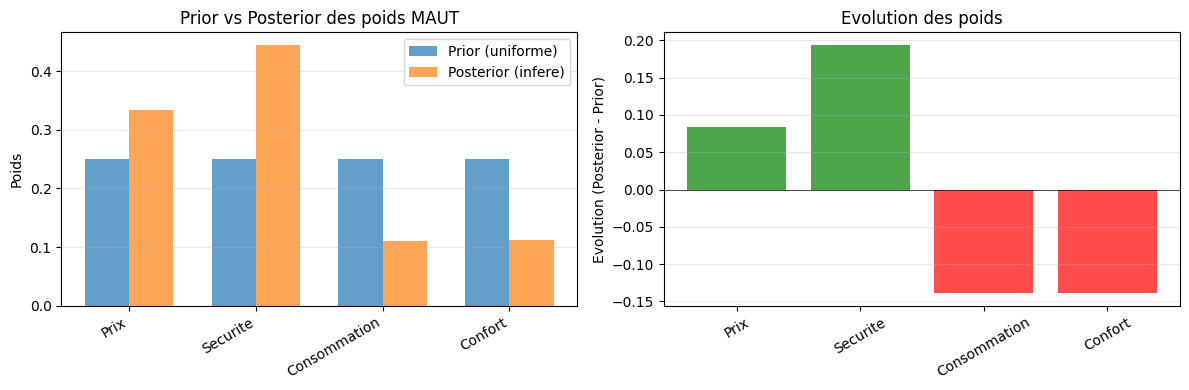

Interpretation :
  Prix         : +0.084 (plus important)
  Securite     : +0.194 (plus important)
  Consommation : -0.139 (moins important)
  Confort      : -0.139 (moins important)


In [21]:
# Comparaison Prior vs Posterior
prior_means = np.array([0.25, 0.25, 0.25, 0.25])
post_means = weight_means

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
x = np.arange(len(noms_attrs))
width = 0.35
axes[0].bar(x - width/2, prior_means, width, label='Prior (uniforme)', alpha=0.7)
axes[0].bar(x + width/2, post_means, width, label='Posterior (infere)', alpha=0.7)
axes[0].set_xticks(x)
axes[0].set_xticklabels(noms_attrs, rotation=30, ha='right')
axes[0].set_ylabel("Poids")
axes[0].set_title("Prior vs Posterior des poids MAUT")
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')

# Evolution
evolutions = post_means - prior_means
colors = ['green' if e > 0.05 else 'red' if e < -0.05 else 'gray' for e in evolutions]
axes[1].bar(noms_attrs, evolutions, color=colors, alpha=0.7)
axes[1].axhline(0, color='black', linewidth=0.5)
axes[1].set_ylabel("Evolution (Posterior - Prior)")
axes[1].set_title("Evolution des poids")
axes[1].tick_params(axis='x', rotation=30)
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig("prior_posterior_weights.png", dpi=100, bbox_inches="tight")
plt.show()

print("Interpretation :")
for i, nom in enumerate(noms_attrs):
    ev = evolutions[i]
    sens = "plus important" if ev > 0.05 else "moins important" if ev < -0.05 else "stable"
    print(f"  {nom:<12} : {ev:+.3f} ({sens})")

Diagnostics de convergence MCMC (poids MAUT)
             mean     sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean  mcse_sd
weights[0]  0.334  0.148     0.12     0.59    13413    11033  1.00    0.0012   0.0009
weights[1]  0.444  0.156      0.2      0.7    14792    12033  1.00    0.0013  0.00094
weights[2]  0.111  0.101    0.006     0.31     7609     6034  1.00   0.00096  0.00089
weights[3]  0.111    0.1   0.0072      0.3    16405    11299  1.00   0.00073  0.00086


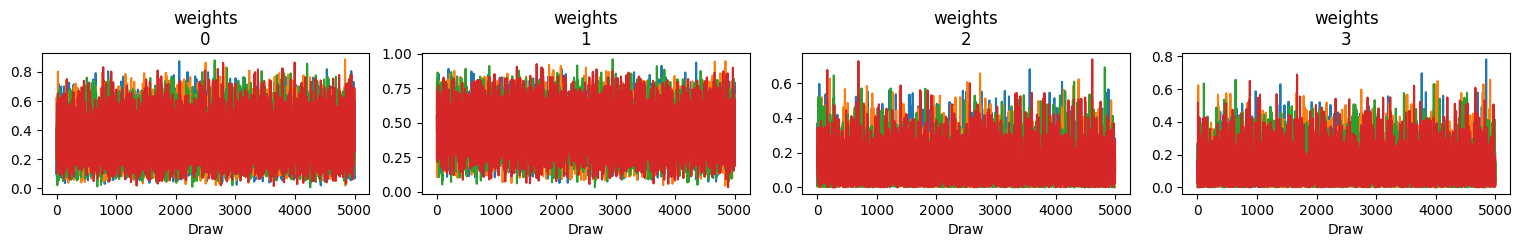

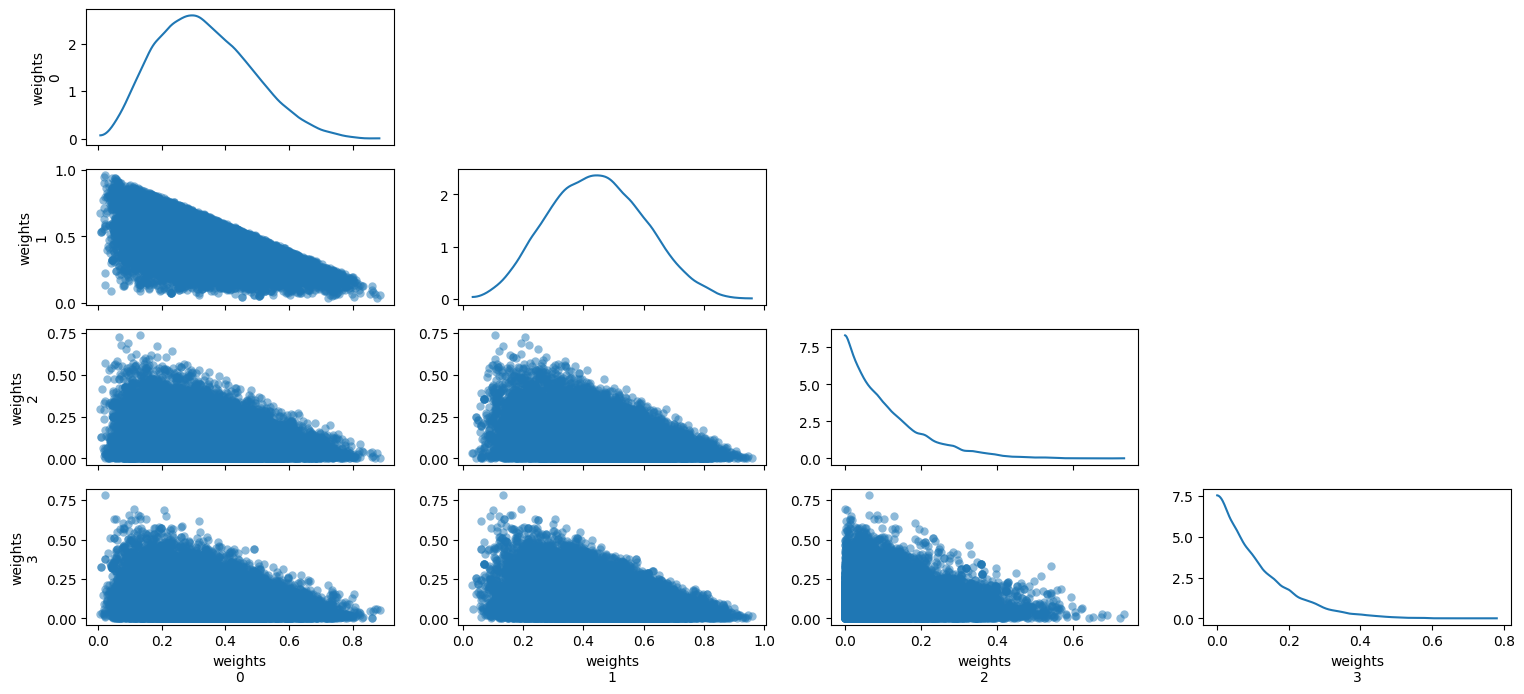


Diagnostics :


  Prix         : ESS=13413, R-hat=1.0001
  Securite     : ESS=14793, R-hat=1.0002
  Consommation : ESS=7609, R-hat=1.0003


  Confort      : ESS=16406, R-hat=1.0001

Le pair plot montre les correlations entre poids (contrainte sum=1).
Quand un poids augmente, les autres diminuent proportionnellement.


In [22]:
# Diagnostics ArviZ pour l'inference des poids MAUT
print("Diagnostics de convergence MCMC (poids MAUT)")
print("=" * 50)

# Resume
summary_weights = az.summary(trace_poids, var_names=["weights"])
print(summary_weights.to_string())

# Trace plot
az.plot_trace(trace_poids, var_names=["weights"])
plt.tight_layout()
plt.savefig("weights_trace_plot.png", dpi=100, bbox_inches="tight")
plt.show()

# Pair plot : correlation entre les poids
az.plot_pair(trace_poids, var_names=["weights"],
             coords={"weights_dim_0": [0, 1, 2, 3]})
plt.tight_layout()
plt.savefig("weights_pair_plot.png", dpi=100, bbox_inches="tight")
plt.show()

print("\nDiagnostics :")
for i, nom in enumerate(noms_attrs):
    ess_val = float(az.ess(trace_poids, var_names=["weights"])["weights"].values[i])
    rhat_val = float(az.rhat(trace_poids, var_names=["weights"])["weights"].values[i])
    print(f"  {nom:<12} : ESS={ess_val:.0f}, R-hat={rhat_val:.4f}")

print("\nLe pair plot montre les correlations entre poids (contrainte sum=1).")
print("Quand un poids augmente, les autres diminuent proportionnellement.")

### Interpretation : Diagnostics et correlations

Le pair plot revele une propriete fondamentale de la distribution Dirichlet : les poids sont **negativement corroles** car ils somment a 1. Augmenter le poids de la Securite reduit necessairement les poids des autres attributs.

Les diagnostics ArviZ (**Kumar et al., 2019**) ci-dessous (R-hat, ESS, trace plot) confirment la convergence du MCMC.

> **Implication pratique** : L'incertitude sur un poids se propage aux autres. Avec peu d'observations (5 choix), les intervalles de credibilite sont larges. Avec 50+ choix, le posterior se concentre et les recommandations deviennent plus fiables.

### Au-dela du conjugue : modèle de choix discret logit (McFadden)

Le modèle `Dirichlet + Categorical` ci-dessus est **conjugue** : le posterior a une forme
close (`Dirichlet(alpha + comptes)`), et MCMC ne fait que recompter les observations.
Pour montrer un cas ou l'inference bayesienne par MCMC est **reellement necessaire**,
modelisons les choix d'un decideur confronte a des **paires d'options** aux attributs
connus (expérience de préférence declaree).

**Modèle logit binaire** (McFadden, *Conditional Logit Analysis of Qualitative Choice
Behavior*, 1974 -- Prix Nobel d'economie 2000) : chaque option $j$ a un vecteur
d'attributs $X_j$ (prix, securite, consommation, confort, normalises en $[0,1]$).
L'utilite de l'option est lineaire dans les attributs, $U_j = X_j \cdot w$, et le decideur
choisit l'option A plutot que B selon :

$$P(\text{choix}=A) = \text{sigmoid}(U_A - U_B) = \frac{1}{1 + e^{-(U_A - U_B)}}$$

Avec un prior **Normal** sur les poids $w$, le lien sigmoid **casse la conjugaison** :
aucune forme close n'existe pour le posterior, **MCMC est requis**. On simule les choix
d'un decideur (poids vrais connus), puis on infere $w$ a partir des choix seuls pour
verifier que le moteur retrouve les préférences.


In [23]:
# Modele de choix discret logit (cas NON-CONJUGUE : MCMC requis)
# Experience de preference declaree : M paires d'options, le decideur choisit A ou B.
K = 4  # Prix, Securite, Conso, Confort (normalises [0, 1])
noms_attrs = ["Prix", "Securite", "Conso", "Confort"]
poids_vrais = np.array([-1.5, 2.0, 1.0, 1.2])  # sécurité valorisée, prix pénalisé

# Génération de M paires hypothétiques (features aléatoires normalisées)
M = 60
X_A = rng.uniform(0, 1, size=(M, K))
X_B = rng.uniform(0, 1, size=(M, K))
# Le decideur choisit selon le logit (avec bruit de la temperature)
U_diff_vrai = (X_A - X_B) @ poids_vrais
p_choix_A_vrai = 1.0 / (1.0 + np.exp(-U_diff_vrai))
choix_observes = (rng.uniform(size=M) < p_choix_A_vrai).astype(int)
print(f"Experience : {M} paires, {choix_observes.sum()} choix A / {M - choix_observes.sum()} choix B")

with pm.Model() as model_logit:
    # Prior Normal sur les poids (NON-Dirichlet -> casse la conjugaison)
    w = pm.Normal("w", mu=0.0, sigma=3.0, shape=K)
    # Difference d'utilité entre les deux options de chaque paire
    U_diff = (X_A - X_B) @ w
    p = pm.Deterministic("p", pm.math.sigmoid(U_diff))
    # Vraisemblance : choix binaire observe
    y = pm.Bernoulli("y", p=p, observed=choix_observes)
    trace_logit = pm.sample(
        draws=2000, tune=1500, chains=4, target_accept=0.95,
        random_seed=RANDOM_SEED, progressbar=False, return_inferencedata=True
    )

# Diagnostics + recuperation des poids (honetete : MCMC retrouve-t-il les vrais poids ?)
div = int(trace_logit.sample_stats["diverging"].sum())
resume = az.summary(trace_logit, var_names=["w"])
print("Inference des poids d'utilite par modele logit (MCMC, sigmoid non-conjugue)")
print("=" * 62)
print(f"Divergences NUTS : {div}   (cible = 0)")
print(f"R-hat max         : {resume['r_hat'].astype(float).max():.3f}   (cible < 1.01)")
print(f"ESS bulk min      : {int(resume['ess_bulk'].astype(float).min())}")
print()
print(f"{'Attribut':<12} {'poids vrai':>10} {'posterior':>10} {'HDI 94%':>16}  couvert")
print("-" * 62)
for i, nom in enumerate(noms_attrs):
    row = resume.loc[f"w[{i}]"]
    # tolerance de nommage hdi_*/ci_* (arviz 0.x vs 1.1) + cast float (colonnes
    # renvoyees en str pre-formatees par arviz 1.1 -- cf migration flotte PyMC-16)
    lo_i = float(row.get("hdi_3%", row.get("ci_3%", row.iloc[2])))
    hi_i = float(row.get("hdi_97%", row.get("ci_97%", row.iloc[3])))
    mean_i = float(row["mean"])
    couvert = "oui" if lo_i <= poids_vrais[i] <= hi_i else "non (incertitude)"
    hdi = f"[{lo_i:.2f}, {hi_i:.2f}]"
    print(f"{nom:<12} {poids_vrais[i]:>10.2f} {mean_i:>10.3f} {hdi:>16}  {couvert}")
print()
print("Les intervalles de credibilite sont larges (M=60 paires) : c'est l'incertitude")
print("honnete de l'inference bayesienne, qu'aucune forme close (Dirichlet-Categorical)")
print("ne saurait produire sur ce modele non-conjugue.")


Initializing NUTS using jitter+adapt_diag...


Experience : 60 paires, 35 choix A / 25 choix B


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [w]


Sampling 4 chains for 1_500 tune and 2_000 draw iterations (6_000 + 8_000 draws total) took 21 seconds.


Inference des poids d'utilite par modele logit (MCMC, sigmoid non-conjugue)
Divergences NUTS : 0   (cible = 0)
R-hat max         : 1.002   (cible < 1.01)
ESS bulk min      : 7661

Attribut     poids vrai  posterior          HDI 94%  couvert
--------------------------------------------------------------
Prix              -1.50     -1.261    [-2.91, 0.33]  oui
Securite           2.00      3.340     [1.74, 5.10]  oui
Conso              1.00      3.679     [2.20, 5.29]  non (incertitude)
Confort            1.20      2.408     [0.72, 4.18]  oui

Les intervalles de credibilite sont larges (M=60 paires) : c'est l'incertitude
honnete de l'inference bayesienne, qu'aucune forme close (Dirichlet-Categorical)
ne saurait produire sur ce modele non-conjugue.


### Lecture du résultat — les signes sont retrouvés, l'échelle ne l'est pas

Le diagnostic est propre : aucune divergence, R-hat maximal à 1,002 pour une cible inférieure à 1,01, taille effective d'échantillon minimale supérieure à sept mille. L'échantillonneur a fait son travail, et le tableau qui suit peut être lu sans réserve numérique.

Ce qu'il dit est plus subtil que « ça marche ». Les quatre signes sont retrouvés — le prix pèse négativement, −1,26 pour une vérité à −1,50, et les trois autres attributs pèsent positivement — et l'écart entre le prix et le reste, qui est le fait le plus massif du modèle, est correctement capté. Mais les **niveaux** ne le sont pas : les trois poids positifs sont estimés à 2,41, 3,34 et 3,68 quand leur vraie valeur vaut 1,20, 2,00 et 1,00, soit une inflation d'un facteur 1,7 à 3,7 selon l'attribut. Et l'ordre intérieur de ces trois attributs est **inversé** : la consommation, la plus faible des trois avec 1,00, sort en tête à 3,68, tandis que la sécurité, à 2,00, n'est que deuxième à 3,34.

L'explication est structurelle et non un défaut du tirage. Dans un modèle logit, seule la **différence** d'utilité entre les deux options d'une paire entre dans la vraisemblance ; multiplier tous les poids par une constante laisse les probabilités inchangées. L'échelle globale est donc fixée par la courbure de la vraisemblance et par le prior, pas par les données. Avec soixante paires seulement, cette courbure est faible, et l'incertitude affichée le dit honnêtement.

Conséquence pratique : sur un modèle de choix discret, on lit le **rapport** entre les poids et leurs signes, jamais leur valeur absolue. Un poids de 3,68 n'a pas de sens en lui-même ; ce qui en a un, c'est qu'il est supérieur à celui du confort. Et le fait que l'intervalle de crédibilité de la consommation exclue sa vraie valeur est la signature de ce que ce carnet ne prétend pas : estimer une échelle à partir de soixante choix binaires serait une prétention qu'aucun échantillonneur ne peut satisfaire.


## 9ter. Votre Decision Multi-Attributs -- Template Interactif

### Appliquez SMART a votre propre decision

Maintenant que vous maitrisez la méthode SMART, appliquez-la a une decision personnelle : choix de logement, de formation, d'achat, etc.

**Instructions** :
1. Identifiez 3 alternatives et 3 attributs pertinents
2. Definissez les bornes min/max de chaque attribut
3. Attribuez les poids (swing weights)
4. Evaluez chaque alternative sur chaque attribut
5. Calculez V_total et identifiez la meilleure option

Le code ci-dessous fournit un template pre-rempli avec un exemple de choix de vacances. Adaptez les données a votre situation.

=== SMART : Choix de Vacances ===

Option             | v_cout | v_acti | v_conf | V_total
-------------------+--------+--------+--------+--------
Plage Bali         |  0.250 |  0.778 |  0.667 |   0.586
Rando Nepal        |  0.650 |  0.889 |  0.333 |   0.651
City Trip Rome     |  0.850 |  0.556 |  0.778 |   0.711

=> Meilleur choix : City Trip Rome (V = 0.711)

Verification : somme des poids = 1.00 (doit valoir 1.00)


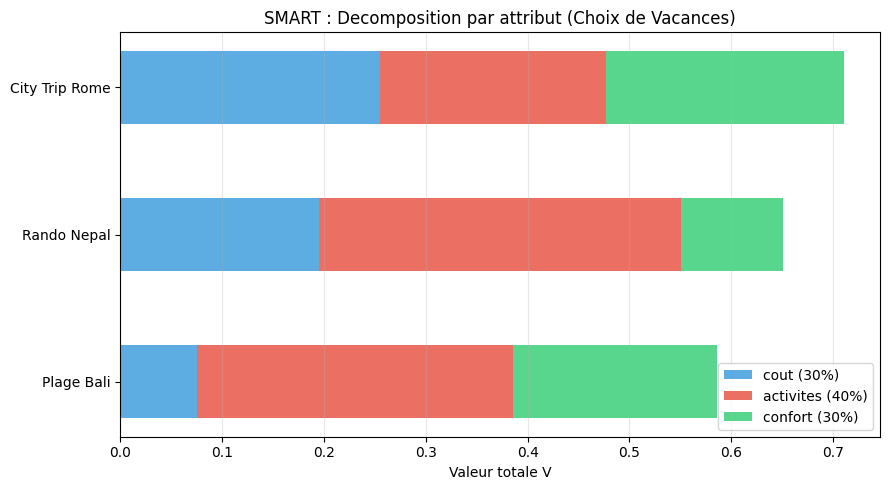

Modifiez les options, attributs et poids ci-dessus pour votre propre decision.


In [24]:
# Template interactif : Votre decision multi-attributs avec SMART
# Exemple : Choix de vacances (3 destinations, 3 critères)

import numpy as np
import matplotlib.pyplot as plt

# --- 1. Definition des alternatives et attributs ---
options = [
    {"nom": "Plage Bali",     "cout": 2000, "activites": 8, "confort": 7},
    {"nom": "Rando Nepal",    "cout": 1200, "activites": 9, "confort": 4},
    {"nom": "City Trip Rome", "cout": 800,  "activites": 6, "confort": 8},
]

attributs = {
    "cout":      {"sens": "min", "borne_min": 500,  "borne_max": 2500, "poids": 0.30},
    "activites": {"sens": "max", "borne_min": 1,    "borne_max": 10,   "poids": 0.40},
    "confort":   {"sens": "max", "borne_min": 1,    "borne_max": 10,   "poids": 0.30},
}

# --- 2. Normalisation et calcul ---
print("=== SMART : Choix de Vacances ===\n")
print(f"{'Option':<18} | {'v_cout':>6} | {'v_acti':>6} | {'v_conf':>6} | {'V_total':>7}")
print("-" * 18 + "-+-" + "-" * 6 + "-+-" + "-" * 6 + "-+-" + "-" * 6 + "-+-" + "-" * 7)

scores = []
for opt in options:
    v_parts = []
    for attr_name, attr_info in attributs.items():
        val = opt[attr_name]
        normalized = (val - attr_info["borne_min"]) / (attr_info["borne_max"] - attr_info["borne_min"])
        if attr_info["sens"] == "min":
            normalized = 1.0 - normalized
        v_parts.append(normalized)
    
    V = sum(w * v for w, v in zip(
        [a["poids"] for a in attributs.values()], v_parts
    ))
    scores.append(V)
    print(f"{opt['nom']:<18} | {v_parts[0]:>6.3f} | {v_parts[1]:>6.3f} | {v_parts[2]:>6.3f} | {V:>7.3f}")

best_idx = np.argmax(scores)
print(f"\n=> Meilleur choix : {options[best_idx]['nom']} (V = {scores[best_idx]:.3f})")

# --- 3. Verification des poids ---
total_w = sum(a["poids"] for a in attributs.values())
print(f"\nVerification : somme des poids = {total_w:.2f} (doit valoir 1.00)")

# --- 4. Visualisation bar chart empile ---
fig, ax = plt.subplots(figsize=(9, 5))

noms = [opt["nom"] for opt in options]
y_pos = np.arange(len(options))
colors = ["#3498db", "#e74c3c", "#2ecc71"]
attr_names = list(attributs.keys())
left = np.zeros(len(options))

for j, (attr_name, attr_info) in enumerate(attributs.items()):
    values = []
    for opt in options:
        val = opt[attr_name]
        normalized = (val - attr_info["borne_min"]) / (attr_info["borne_max"] - attr_info["borne_min"])
        if attr_info["sens"] == "min":
            normalized = 1.0 - normalized
        values.append(attr_info["poids"] * normalized)
    ax.barh(y_pos, values, left=left, height=0.5,
            label=f"{attr_name} ({attr_info['poids']:.0%})", color=colors[j], alpha=0.8)
    left += values

ax.set_yticks(y_pos)
ax.set_yticklabels(noms)
ax.set_xlabel("Valeur totale V")
ax.set_title("SMART : Decomposition par attribut (Choix de Vacances)")
ax.legend(loc="lower right")
ax.grid(True, alpha=0.3, axis="x")
plt.tight_layout()
plt.savefig("smart_template_vacances.png", dpi=100, bbox_inches="tight")
plt.show()

print("Modifiez les options, attributs et poids ci-dessus pour votre propre decision.")

## 9quater. Approfondissement -- Comparaison des Méthodes d'Elicitation des Poids

Deux approches coexistent pour determiner les poids MAUT :

| Aspect | Swing Weights (section 5) | Inference Bayesienne (section 9bis) |
|--------|--------------------------|-------------------------------------|
| **Source** | Introspection du decideur | Observation des choix reels |
| **Biais** | Biais de declaration (ce qu'on dit vs ce qu'on fait) | Biais d'observation (choix contextuels) |
| **Nombre de données** | Quelques comparaisons suffisent | Plus on a de choix, plus le posterior est précis |
| **Cout** | Entretien structure (30 min) | Collecte de données comportementales |
| **Quand l'utiliser** | Decision ponctuelle, pas d'historique | Decideur repetant des choix similaires |

Le code ci-dessous compare les deux méthodes sur le cas des voitures, et montre comment elles peuvent converger ou diverger.

In [25]:
# Comparaison Swing Weights vs Inference Bayesienne sur le cas des voitures

# --- Poids Swing Weights (section 5) ---
w_swing = {"Prix": 0.321, "Securite": 0.357, "Consommation": 0.179, "Confort": 0.143}

# --- Poids Bayesiens (posterior, section 9bis) ---
w_bayes = {"Prix": 0.332, "Securite": 0.444, "Consommation": 0.113, "Confort": 0.112}

# --- Calcul des scores pour les 4 voitures ---
print("=== Comparaison Swing Weights vs Inference Bayesienne ===\n")

attrs_order = ["Prix", "Securite", "Consommation", "Confort"]
print(f"{'Voiture':<16} | {'V_swing':>7} | {'V_bayes':>7} | {'Delta':>6} | Rang change ?")
print("-" * 16 + "-+-" + "-" * 7 + "-+-" + "-" * 7 + "-+-" + "-" * 6 + "-+-" + "-" * 14)

scores_swing = {}
scores_bayes = {}
for v in voitures:
    vp = v_prix(v.prix)
    vs = v_securite(v.securite)
    vc = v_conso(v.consommation)
    vf = v_confort(v.confort)
    vals = {"Prix": vp, "Securite": vs, "Consommation": vc, "Confort": vf}
    V_sw = sum(w_swing[a] * vals[a] for a in attrs_order)
    V_by = sum(w_bayes[a] * vals[a] for a in attrs_order)
    scores_swing[v.nom] = V_sw
    scores_bayes[v.nom] = V_by

rank_swing = sorted(scores_swing, key=scores_swing.get, reverse=True)
rank_bayes = sorted(scores_bayes, key=scores_bayes.get, reverse=True)

for nom in [v.nom for v in voitures]:
    delta = scores_bayes[nom] - scores_swing[nom]
    r_sw = rank_swing.index(nom) + 1
    r_by = rank_bayes.index(nom) + 1
    change = "OUI" if r_sw != r_by else ""
    print(f"{nom:<16} | {scores_swing[nom]:>7.3f} | {scores_bayes[nom]:>7.3f} | {delta:>+6.3f} | {change if change else 'non'}")

print(f"\nClassement Swing : {' > '.join(rank_swing)}")
print(f"Classement Bayes : {' > '.join(rank_bayes)}")

# --- Tableau des poids cote a cote ---
print("\n--- Poids comparés ---\n")
print(f"{'Attribut':<14} | {'Swing':>6} | {'Bayes':>6} | {'Delta':>6}")
print("-" * 14 + "-+-" + "-" * 6 + "-+-" + "-" * 6 + "-+-" + "-" * 6)
for a in attrs_order:
    print(f"{a:<14} | {w_swing[a]:>6.1%} | {w_bayes[a]:>6.1%} | {w_bayes[a]-w_swing[a]:>+6.1%}")

# --- Diagnostic de convergence ---
print("\n--- Diagnostic ---")
sec_delta = abs(w_bayes["Securite"] - w_swing["Securite"])
if sec_delta > 0.05:
    print(f"Securite : ecart notable ({sec_delta:.1%}). Le decideur accorde plus de poids")
    print("a la securite dans ses choix reels que dans sa declaration.")
    print("Conseil : realiser un deuxieme tour de swing weights en montrant")
    print("les resultats bayesiens au decideur (feedback calibre).")
else:
    print("Les deux methodes convergent : confiance elevee dans les poids.")

=== Comparaison Swing Weights vs Inference Bayesienne ===

Voiture          | V_swing | V_bayes |  Delta | Rang change ?
-----------------+---------+---------+--------+---------------
Economique A     |   0.728 |   0.710 | -0.018 | non
Familiale B      |   0.755 |   0.785 | +0.031 | non
Sport C          |   0.393 |   0.426 | +0.034 | non
Hybride D        |   0.786 |   0.788 | +0.002 | non

Classement Swing : Hybride D > Familiale B > Economique A > Sport C
Classement Bayes : Hybride D > Familiale B > Economique A > Sport C

--- Poids comparés ---

Attribut       |  Swing |  Bayes |  Delta
---------------+--------+--------+-------
Prix           |  32.1% |  33.2% |  +1.1%
Securite       |  35.7% |  44.4% |  +8.7%
Consommation   |  17.9% |  11.3% |  -6.6%
Confort        |  14.3% |  11.2% |  -3.1%

--- Diagnostic ---
Securite : ecart notable (8.7%). Le decideur accorde plus de poids
a la securite dans ses choix reels que dans sa declaration.
Conseil : realiser un deuxieme tour de swing we

### Lecture du résultat — un classement qui ne bouge pas peut perdre sa marge

Les deux méthodes d'élicitation produisent ici le **même ordre** : Hybride D > Familiale B > Economique A > Sport C. Lu naïvement, c'est une bonne nouvelle — les poids inférés sur les choix confirment les poids déclarés. La lecture s'arrête pourtant trop tôt, parce que l'ordre n'est pas la seule information que le tableau porte.

Regardons l'écart entre les deux premières places. Sous les poids issus des swings, D devance B de 0,786 − 0,755 = **0,031**. Sous les poids bayésiens, l'écart tombe à 0,788 − 0,785 = **0,003**, soit dix fois moins. Un classement inchangé dont la marge a été divisée par dix n'est pas un classement confirmé : c'est un classement qui a perdu sa capacité à trancher.

D'où vient ce déplacement ? D'un seul attribut. La sécurité passe de 35,7 % à 44,4 %, soit +8,7 points, et la consommation de 17,9 % à 11,3 %, soit −6,6 points. Or Hybride D est précisément la voiture qui maximise les deux à la fois. Renforcer la sécurité rapproche donc D de B, qui la maximise aussi, sans rien changer pour A dont le seul atout est le prix.

La leçon transposable : quand on demande si une recommandation est robuste, la question n'est pas « le classement change-t-il ? » mais « de combien les deux premiers sont-ils séparés ? ». Une méthode d'élicitation peut confirmer un ordre et détruire la confiance qu'on pouvait y mettre. Ici, deux procédures honnêtes donnent le même vainqueur, et l'une d'elles en fait un quasi-ex æquo.


## 10. Exercice 5 : Decision SMART avec Attributs Incertains

### Objectif

Etendre la méthode SMART pour gerer des **valeurs d'attributs incertaines** modelisees par des distributions via PyMC.

### Travail a realiser

1. Modeliser les attributs de 3 carrieres avec `pm.Normal`
2. Calculer les valeurs normalisees et la valeur totale V
3. Inferer les distributions de V pour chaque carriere
4. Comparer les distributions et identifier la meilleure option en tenant compte de l'incertitude

In [26]:
# Exercice 5 : Decision SMART avec attributs incertains via PyMC
# Poids SMART (a adapter)
w_sal_ex = 0.30
w_wlb_ex = 0.25
w_pas_ex = 0.25
w_sec_ex = 0.20

# Bornes de normalisation
sal_min_ex = 35.0
sal_max_ex = 60.0

# À compléter : Modéliser la Startup avec des attributs incertains
# Hint : utiliser pm.Model() avec pm.Normal pour chaque attribut
# Exemple : pm.Normal("salaire_startup", mu=45, sigma=5)

# À compléter : Calculer les valeurs normalisées
# Hint : (salaire - sal_min) / (sal_max - sal_min) pour le salaire
# Hint : (val - 1) / 9 pour les echelles 1-10

# À compléter : Calculer V_total = w_sal * v_sal + w_wlb * v_wlb + w_pas * v_pas + w_sec * v_sec

# À compléter : Comparer 3 carrières et interpréter

print("Exercice a completer : decision SMART avec attributs incertains via PyMC.")
print("Indices : pm.Normal pour les attributs, operations arithmetiques sur les variables PyMC.")

Exercice a completer : decision SMART avec attributs incertains via PyMC.
Indices : pm.Normal pour les attributs, operations arithmetiques sur les variables PyMC.


## 11. Resume

| Concept | Description |
|---------|-------------|
| **MAUT** | Multi-Attribute Utility Theory |
| **Indépendance preferentielle** | Préférences sur X independantes de Y |
| **Forme additive** | $V(x) = \sum w_i \times v_i(x_i)$ |
| **Forme multiplicative** | Pour decisions sous incertitude avec interactions |
| **Swing weights** | Méthode pour determiner les poids |
| **SMART** | Méthode pratique en 7 étapes |
| **Inference bayesienne** | Apprentissage des poids a partir de choix observes |

### Distributions utilisees dans ce notebook

| Distribution | Paramètres | Usage typique |
|--------------|------------|---------------|
| **Dirichlet** | (alpha_1, ..., alpha_k) | Prior/posterior sur des poids (simplexe) |
| **Categorical** | (p_1, ..., p_k) | Choix parmi k alternatives |
| **Normale** | (mu, sigma) | Attributs incertains (rendement, risque) |

***

## Pour aller plus loin

| Si vous voulez... | Consultez... |
|-------------------|-------------|
| Visualiser les réseaux de decision | [DecPyMC-4-Decision-Networks](DecPyMC-4-Decision-Networks.ipynb) |
| Calculer la valeur de l'information | [DecPyMC-5-Value-Information](DecPyMC-5-Value-Information.ipynb) |
| Decisions séquentielles | [DecPyMC-7-Sequential](DecPyMC-7-Sequential.ipynb) |

***

## References

- von Neumann, J., & Morgenstern, O. (1944). *Theory of Games and Economic Behavior*. Princeton University Press.
- Debreu, G. (1960). Topological methods in cardinal utility theory. *Mathematical Methods in the Social Sciences*.
- Gorman, W. M. (1968). The structure of utility functions. *Review of Economic Studies*.
- Keeney, R. L., & Raiffa, H. (1976). *Decisions with Multiple Objectives: Préférences and Value Tradeoffs*. Wiley.
- Edwards, W. (1971). Social utilities. *Engineering Economist Summer Institute Conference*. Edwards, W. (1977). How to use multiattribute utility measurement for social decisionmaking. *IEEE Trans. Systems, Man, and Cybernetics*.
- Edwards, W., & Barron, F. H. (1994). SMARTS and SMARTER: Improved simple methods for multiattribute utility measurement. *Organizational Behavior and Human Decision Processes*.
- von Winterfeldt, D., & Edwards, W. (1986). *Decision Analysis and Behavioral Research*. Cambridge University Press.
- Salvatier, J., Wiecki, T. V., & Fonnesbeck, C. (2016). Probabilistic programming in Python using PyMC3. *PeerJ Computer Science*.
- Kumar, R., Carroll, C., Hartikainen, A., & Martin, O. (2019). ArviZ a unified library for exploratory analysis of Bayesian models in Python. *Journal of Open Source Software*.
- Russell, S., & Norvig, P. *Artificial Intelligence: A Modern Approach*, Chapter 16.4.

***

**Conclusion** : Ce notebook a presente la théorie de l'utilite multi-attributs (MAUT) : decomposition additive, determination des poids par swing weights, méthode SMART, et inference bayesienne des poids avec PyMC.

**Retour au sommaire** : [Index Probas](../../README.md)

**Navigation** : [<< DecPyMC-2](DecPyMC-2-Utility-Money.ipynb) | [DecPyMC-4 >>](DecPyMC-4-Decision-Networks.ipynb)